# Лекция 7. Закон больших чисел и центральная предельная теорема

Демонстрационный ноутбук к лекции. Здесь ничего не нужно дописывать: запускайте ячейки по порядку, меняйте параметры и смотрите на графики.

1. **Неравенства Маркова и Чебышёва**: насколько граница больше настоящей вероятности для разных законов.
2. **Закон больших чисел**: бегущее среднее, разброс среднего $\sigma/\sqrt{n}$, теорема Бернулли, рулетка, «ошибка игрока», закон Коши, рейтинг районов.
3. **Центральная предельная теорема**: доска Гальтона, сумма кубиков, «колокол из чего угодно», теорема Муавра — Лапласа.
4. **Задачи лекции**: проверяем ответы симуляцией.

### Как открыть ноутбук в Google Colab

1. Скачайте файл `.ipynb` на свой компьютер.
2. Откройте [colab.research.google.com](https://colab.research.google.com) и войдите в свой Google-аккаунт.
3. Выберите «Файл → Загрузить блокнот» (File → Upload notebook), перейдите на вкладку «Загрузить» и выберите скачанный файл. Можно просто перетащить файл в окно.
4. Ноутбук сохранится на вашем Google Диске в папке «Colab Notebooks». В следующий раз открывайте его оттуда.
5. «Среда выполнения → Выполнить все» (Runtime → Run all) запускает все ячейки, `Shift+Enter` — одну.

Ячейки с ползунками (`interact`) работают в Colab и Jupyter: двигайте ползунок, и график перерисуется.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (9, 4.2)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
BLUE, LBLUE, GRAY, DARK = "#1F6BFF", "#BFD3FF", "#9CA3AF", "#111827"

def Phi(x):
    # Функция Лапласа, как на семинарах: Φ(x) = P(0 < Z < x) для стандартного нормального Z
    return stats.norm.cdf(x) - 0.5

try:
    from ipywidgets import interact, IntSlider, FloatSlider, Dropdown
    HAS_WIDGETS = True
except ImportError:
    HAS_WIDGETS = False
    print("ipywidgets не найден: ползунки не появятся, статические графики работают")

print("Φ(1) =", round(Phi(1), 4), " Φ(2) =", round(Phi(2), 4), " Φ(3) =", round(Phi(3), 4))

Φ(1) = 0.3413  Φ(2) = 0.4772  Φ(3) = 0.4987


---
## 1. Неравенства Маркова и Чебышёва

**Неравенство Маркова.** Для $X\ge 0$ и $a>0$:
$$P(X\ge a)\le\frac{E(X)}{a}.$$

**Неравенство Чебышёва.** Для любой величины с конечной дисперсией и $\varepsilon>0$:
$$P(|X-E(X)|\ge\varepsilon)\le\frac{\mathrm{Var}(X)}{\varepsilon^2}.$$

Оба неравенства — гарантии «не больше». Посмотрим, насколько они больше настоящих вероятностей.

### 1.1. Марков: граница против настоящего хвоста

Возьмём три неотрицательных закона с одним и тем же средним $E(X)=100$ и сравним $P(X\ge a)$ с границей $100/a$.

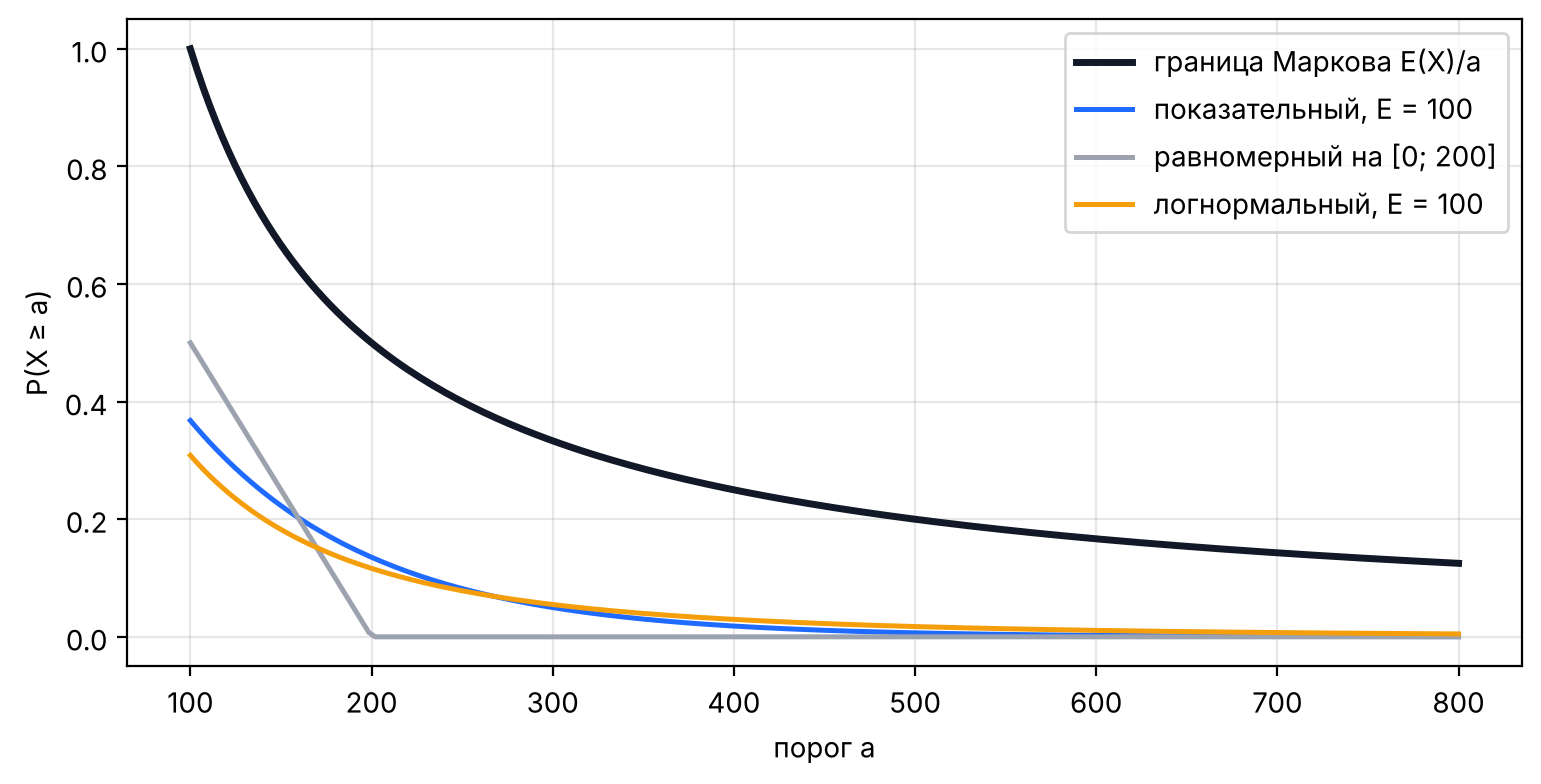

,закон,E(X),P(X ≥ 500),граница Маркова
0,"показательный, E = 100",100.0,0.0067,0.2
1,равномерный на [0; 200],100.0,0.0000,0.2
2,"логнормальный, E = 100",100.0,0.0175,0.2


In [2]:
laws = {
    "показательный, E = 100": stats.expon(scale=100),
    "равномерный на [0; 200]": stats.uniform(0, 200),
    "логнормальный, E = 100": stats.lognorm(s=1, scale=100 / np.exp(0.5)),
}
a = np.linspace(100, 800, 200)
plt.plot(a, 100 / a, color=DARK, lw=2.5, label="граница Маркова E(X)/a")
for (name, d), c in zip(laws.items(), [BLUE, GRAY, "#F59E0B"]):
    plt.plot(a, d.sf(a), color=c, lw=1.8, label=name)
plt.xlabel("порог a"); plt.ylabel("P(X ≥ a)"); plt.legend(); plt.show()

rows = []
for name, d in laws.items():
    rows.append({"закон": name, "E(X)": round(d.mean(), 1), "P(X ≥ 500)": round(d.sf(500), 4), "граница Маркова": 100 / 500})
pd.DataFrame(rows)

Граница везде выше настоящих вероятностей — так и должно быть. Но есть закон, на котором она достигается точно: величина принимает значение $0$ с вероятностью $0{,}8$ и значение $500$ с вероятностью $0{,}2$. Её среднее $0{,}2\cdot 500=100$, а $P(X\ge 500)=0{,}2$ — ровно граница. Неравенство улучшить нельзя, если про закон ничего не известно.

In [3]:
x = rng.choice([0, 500], p=[0.8, 0.2], size=100_000)
print("выборочное среднее:", x.mean().round(1))
print("доля X ≥ 500:      ", (x >= 500).mean().round(3), "   граница Маркова: 100/500 =", 100 / 500)

выборочное среднее: 99.4
доля X ≥ 500:       0.199    граница Маркова: 100/500 = 0.2


### 1.2. Чебышёв: «в сигмах»

Подставим $\varepsilon=k\sigma$: $P(|X-E(X)|\ge k\sigma)\le 1/k^2$. Сравним с настоящими вероятностями для разных законов. Вероятности посчитаем симуляцией: 1 000 000 значений каждого закона.

In [4]:
N = 1_000_000
samples = {
    "нормальный": rng.normal(0, 1, N),
    "равномерный": rng.uniform(0, 1, N),
    "показательный": rng.exponential(1, N),
    "Пуассона, λ = 2": rng.poisson(2, N),
}
ks = np.array([1.5, 2, 2.5, 3])
table = {"граница Чебышёва 1/k²": 1 / ks**2}
for name, x in samples.items():
    z = np.abs(x - x.mean()) / x.std()
    table[name] = [(z >= k).mean() for k in ks]
pd.DataFrame(table, index=[f"k = {k}" for k in ks]).round(4)

,граница Чебышёва 1/k²,нормальный,равномерный,показательный,"Пуассона, λ = 2"
k = 1.5,0.4444,0.1341,0.1339,0.0820,0.0525
k = 2.0,0.2500,0.0455,0.0000,0.0498,0.0525
k = 2.5,0.1600,0.0125,0.0000,0.0303,0.0164
k = 3.0,0.1111,0.0027,0.0000,0.0184,0.0045


Для нормального закона настоящая вероятность отойти на $3\sigma$ — около $0{,}27\%$, а Чебышёв гарантирует только «не больше $11\%$». Зато граница верна для **любого** закона, даже самого неудобного.

### 1.3. Задача «Фасовка»

Средняя масса пакета 1000 г, $\sigma=10$ г. Чебышёв: $P(|X-1000|<20)\ge 1-\dfrac{100}{400}=0{,}75$. Проверим на нескольких законах с одинаковыми $E$ и $\sigma$.

In [5]:
N = 1_000_000
s = 10
packs = {
    "нормальный": rng.normal(1000, s, N),
    "равномерный": rng.uniform(1000 - s * np.sqrt(3), 1000 + s * np.sqrt(3), N),
    "показательный сдвиг": 1000 - s + rng.exponential(s, N),
    "«худший»: 1000 ± 20 или ровно 1000": rng.choice([980, 1000, 1020], p=[0.125, 0.75, 0.125], size=N),
}
for name, x in packs.items():
    print(f"{name:38s} σ = {x.std():5.2f}   P(|X − 1000| < 20) = {(np.abs(x - 1000) < 20).mean():.4f}")
print("\nЧебышёв: не меньше 0,75.  Для нормального закона формула: 2Φ(2) =", round(2 * Phi(2), 4))

нормальный                             σ =  9.99   P(|X − 1000| < 20) = 0.9544
равномерный                            σ = 10.00   P(|X − 1000| < 20) = 1.0000
показательный сдвиг                    σ = 10.00   P(|X − 1000| < 20) = 0.9502
«худший»: 1000 ± 20 или ровно 1000     σ = 10.01   P(|X − 1000| < 20) = 0.7496

Чебышёв: не меньше 0,75.  Для нормального закона формула: 2Φ(2) = 0.9545


Последний закон устроен так, что граница Чебышёва почти достигается: четверть пакетов отклоняется ровно на 20 г.

---
## 2. Закон больших чисел

Пусть $X_1,\dots,X_n$ — независимые наблюдения одной величины, $E(X_i)=a$, $\mathrm{Var}(X_i)=\sigma^2$, и $\bar X=\frac{1}{n}(X_1+\ldots+X_n)$. На лекции мы получили
$$E(\bar X)=a,\qquad \mathrm{Var}(\bar X)=\frac{\sigma^2}{n},\qquad P(|\bar X-a|\ge\varepsilon)\le\frac{\sigma^2}{n\varepsilon^2}\xrightarrow[n\to\infty]{}0.$$

### 2.1. Бегущее среднее

Бросаем монету и после каждого броска считаем долю орлов. Синяя полоса — коридор $0{,}5\pm 2\sigma/\sqrt{n}$, где $\sigma=0{,}5$.

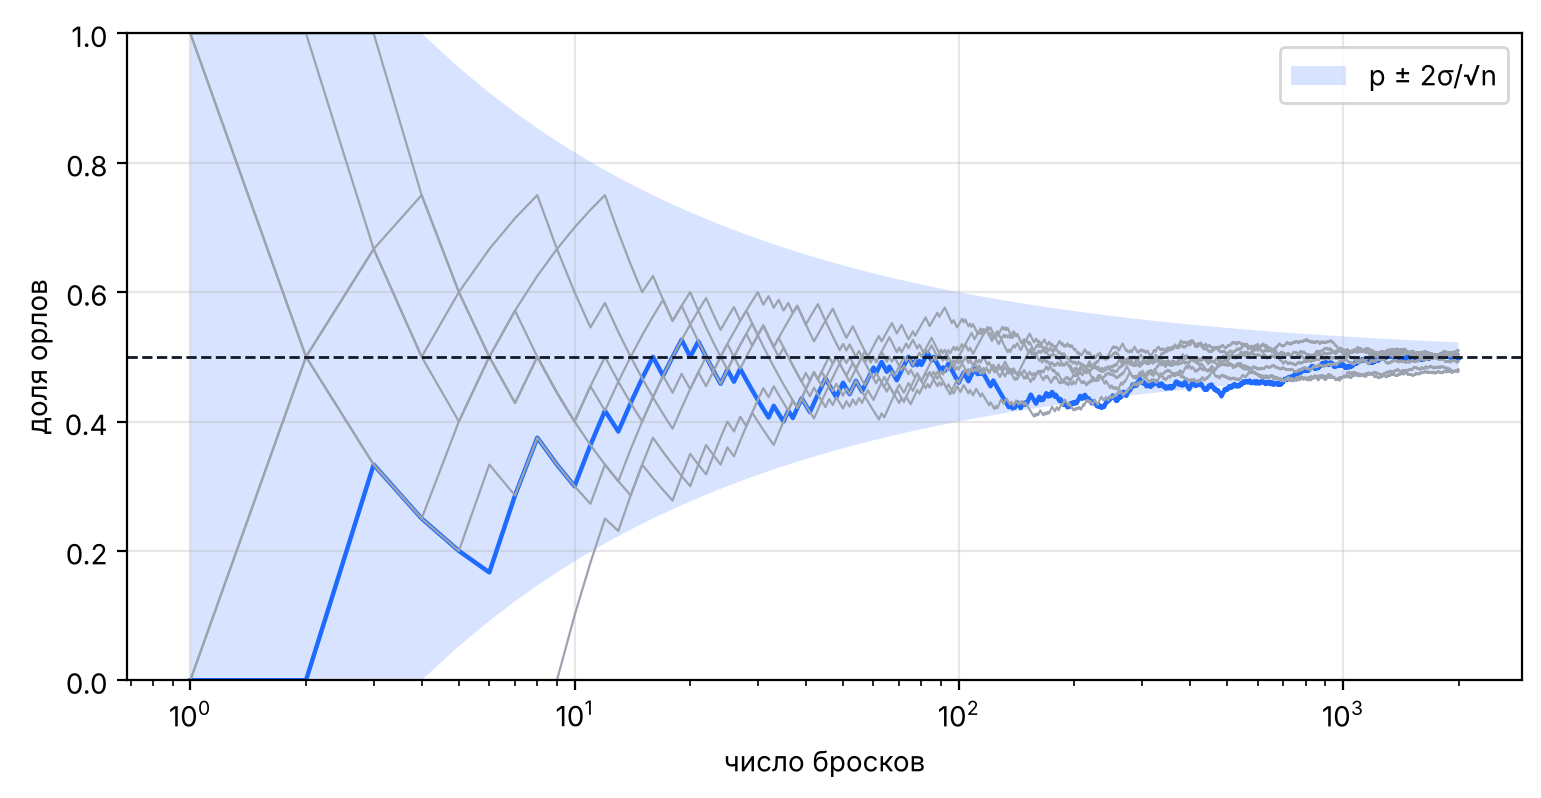

In [6]:
def running_mean_plot(n_flips=2000, n_series=8, p=0.5):
    k = np.arange(1, n_flips + 1)
    s = np.sqrt(p * (1 - p))
    plt.fill_between(k, p - 2 * s / np.sqrt(k), p + 2 * s / np.sqrt(k), color=LBLUE, alpha=0.6, lw=0, label="p ± 2σ/√n")
    for i in range(n_series):
        flips = rng.random(n_flips) < p
        plt.plot(k, np.cumsum(flips) / k, color=BLUE if i == 0 else GRAY, lw=1.6 if i == 0 else 0.8)
    plt.axhline(p, color=DARK, ls="--", lw=1)
    plt.xscale("log"); plt.ylim(0, 1); plt.xlabel("число бросков"); plt.ylabel("доля орлов"); plt.legend()
    plt.show()

running_mean_plot()

In [7]:
if HAS_WIDGETS:
    interact(running_mean_plot,
             n_flips=IntSlider(2000, 100, 100_000, step=100, description="бросков"),
             n_series=IntSlider(8, 1, 30, description="серий"),
             p=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, description="p"));

interactive(children=(IntSlider(value=2000, description='бросков', max=100000, min=100, step=100), IntSlider(v…

### 2.2. Разброс среднего: закон $\sigma/\sqrt{n}$

Время ожидания автобуса — показательный закон со средним 12 мин и $\sigma=12$ мин. Для каждого $n$ соберём 20 000 средних по $n$ ожиданиям и сравним их стандартное отклонение с формулой $\sigma/\sqrt{n}$.

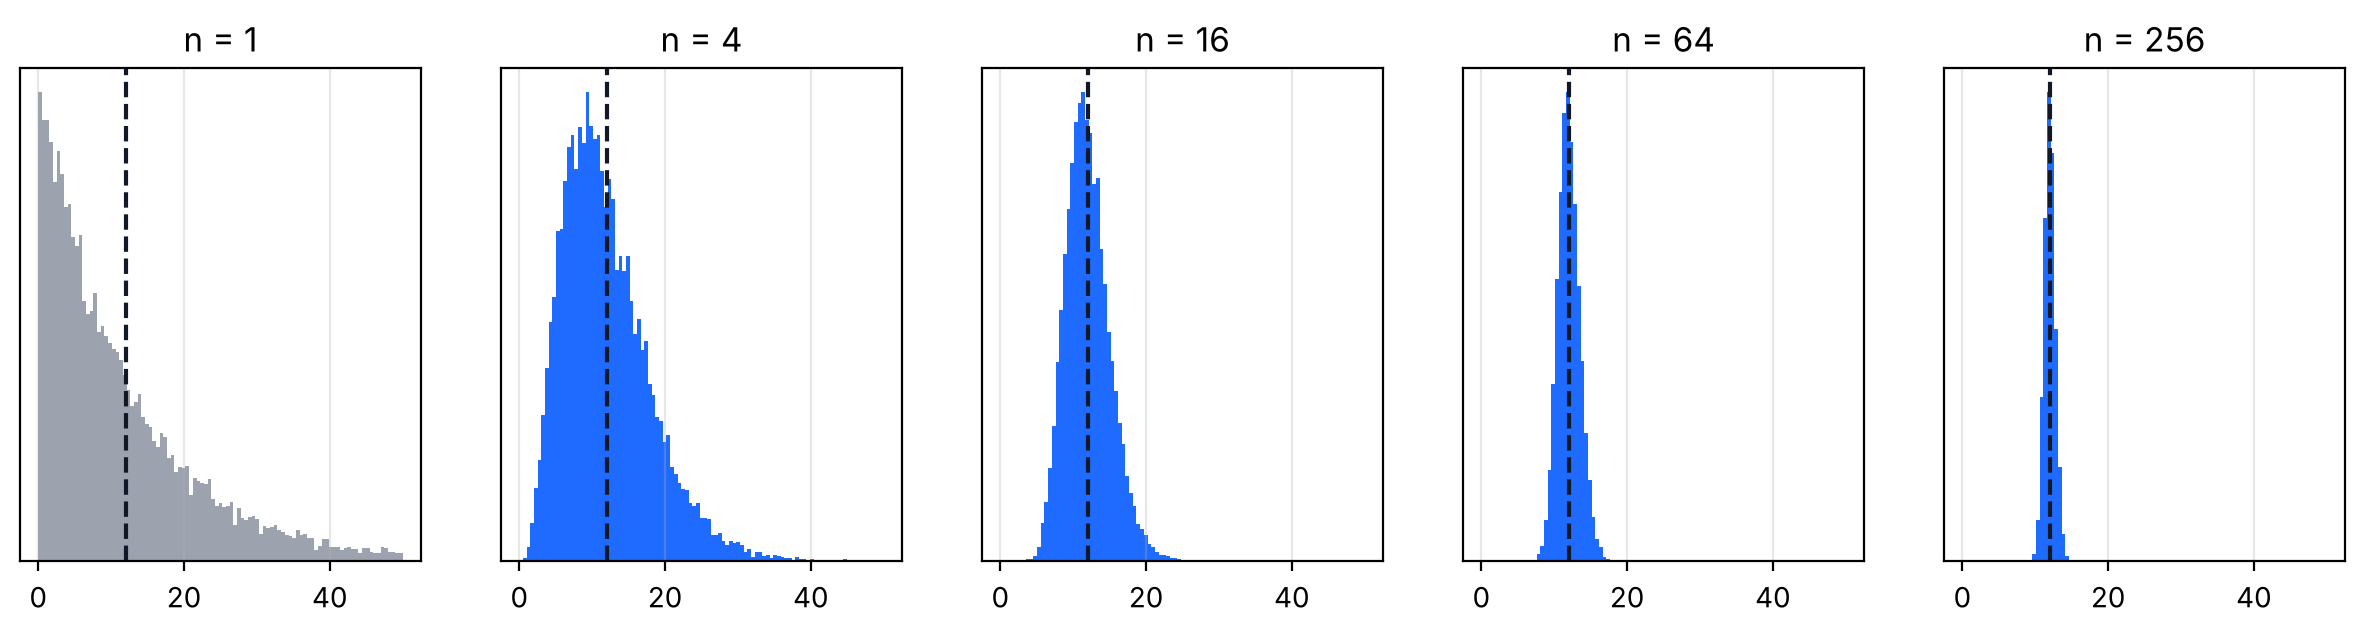

,n,разброс средних (симуляция),σ/√n (формула)
0,1,11.991,12.00
1,4,6.021,6.00
2,16,3.034,3.00
3,64,1.511,1.50
4,256,0.754,0.75


In [8]:
ns = [1, 4, 16, 64, 256]
fig, axs = plt.subplots(1, len(ns), figsize=(15, 3.2), sharex=True)
rows = []
for ax, n in zip(axs, ns):
    means = rng.exponential(12, size=(20_000, n)).mean(axis=1)
    ax.hist(means, bins=np.linspace(0, 50, 100), color=GRAY if n == 1 else BLUE, density=True)
    ax.axvline(12, color=DARK, ls="--"); ax.set_title(f"n = {n}"); ax.set_yticks([])
    rows.append({"n": n, "разброс средних (симуляция)": means.std(), "σ/√n (формула)": 12 / np.sqrt(n)})
plt.show()
pd.DataFrame(rows).round(3)

Каждый раз, когда выборка увеличивается вчетверо, разброс уменьшается вдвое.

### 2.3. Вероятность промаха и граница Чебышёва

Насколько часто среднее $n$ ожиданий промахивается мимо 12 мин больше чем на $\varepsilon=2$ мин? Сравним с гарантией $\sigma^2/(n\varepsilon^2)$.

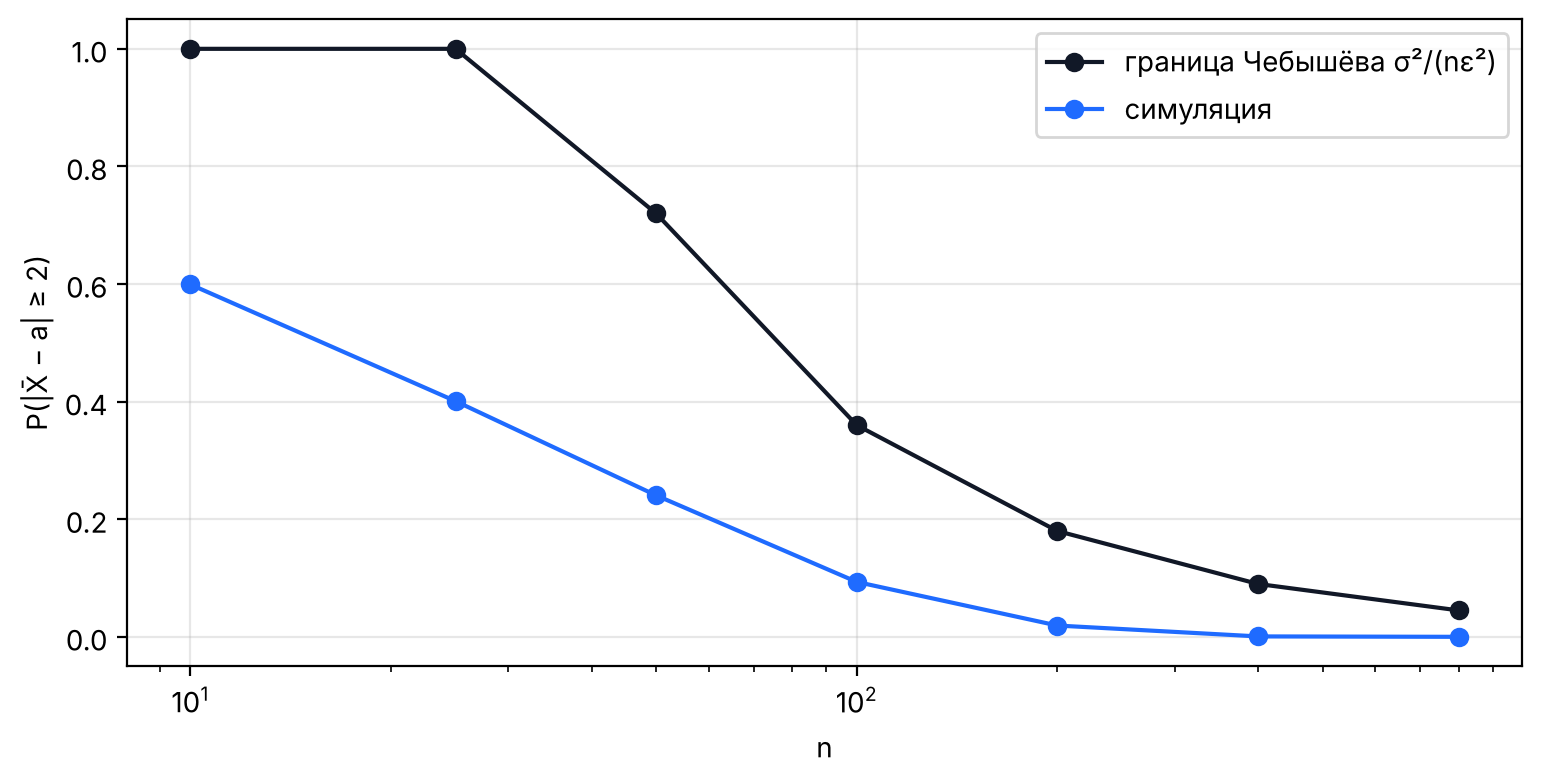

,n,симуляция,Чебышёв
0,10,0.5992,1.000
1,25,0.4008,1.000
2,50,0.2406,0.720
3,100,0.0934,0.360
4,200,0.0192,0.180
5,400,0.0008,0.090
6,800,0.0000,0.045


In [9]:
eps, a, sigma = 2, 12, 12
ns = np.array([10, 25, 50, 100, 200, 400, 800])
miss = [(np.abs(rng.exponential(a, size=(20_000, n)).mean(1) - a) >= eps).mean() for n in ns]
bound = np.minimum(sigma**2 / (ns * eps**2), 1)
plt.plot(ns, bound, "o-", color=DARK, label="граница Чебышёва σ²/(nε²)")
plt.plot(ns, miss, "o-", color=BLUE, label="симуляция")
plt.xscale("log"); plt.xlabel("n"); plt.ylabel("P(|X̄ − a| ≥ 2)"); plt.legend(); plt.show()
pd.DataFrame({"n": ns, "симуляция": miss, "Чебышёв": bound}).round(4)

Обе кривые идут к нулю — это и есть закон больших чисел. Чебышёв сильно завышает вероятность промаха, но для доказательства сходимости этого достаточно.

### 2.4. Теорема Бернулли: сколько раз бросить монету

Хотим, чтобы с вероятностью не меньше $0{,}95$ частота орлов отличалась от $0{,}5$ меньше чем на $0{,}05$. Чебышёв гарантирует, что хватит $n=2000$, а ЦПТ говорит, что хватит $n\approx 385$. Проверим оба ответа: бросим монету $n$ раз, повторим опыт 100 000 раз.

In [10]:
for n in [100, 385, 2000]:
    freq = rng.binomial(n, 0.5, size=100_000) / n
    print(f"n = {n:5d}:  P(|m/n − 0,5| < 0,05) ≈ {(np.abs(freq - 0.5) < 0.05).mean():.4f}")

n =   100:  P(|m/n − 0,5| < 0,05) ≈ 0.6820
n =   385:  P(|m/n − 0,5| < 0,05) ≈ 0.9472
n =  2000:  P(|m/n − 0,5| < 0,05) ≈ 1.0000


При $n=385$ вероятность уже около $0{,}95$, при $n=2000$ — почти единица: гарантия Чебышёва с большим запасом.

### 2.5. Почему казино не рискует

Ставка 100 руб. на красное: выигрыш $+100$ с вероятностью $18/37$, проигрыш $-100$ с вероятностью $19/37$. Ожидание одной ставки $-100/37\approx-2{,}70$ руб.

Один игрок, 1000 ставок:
  средний итог    -2696 руб., разброс   3159 руб., в плюсе 18.8% игроков
Казино, 10 млн ставок: в среднем 27.03 млн руб., разброс 0.31 млн руб.
  доля «вечеров», когда казино в минусе: 0.0


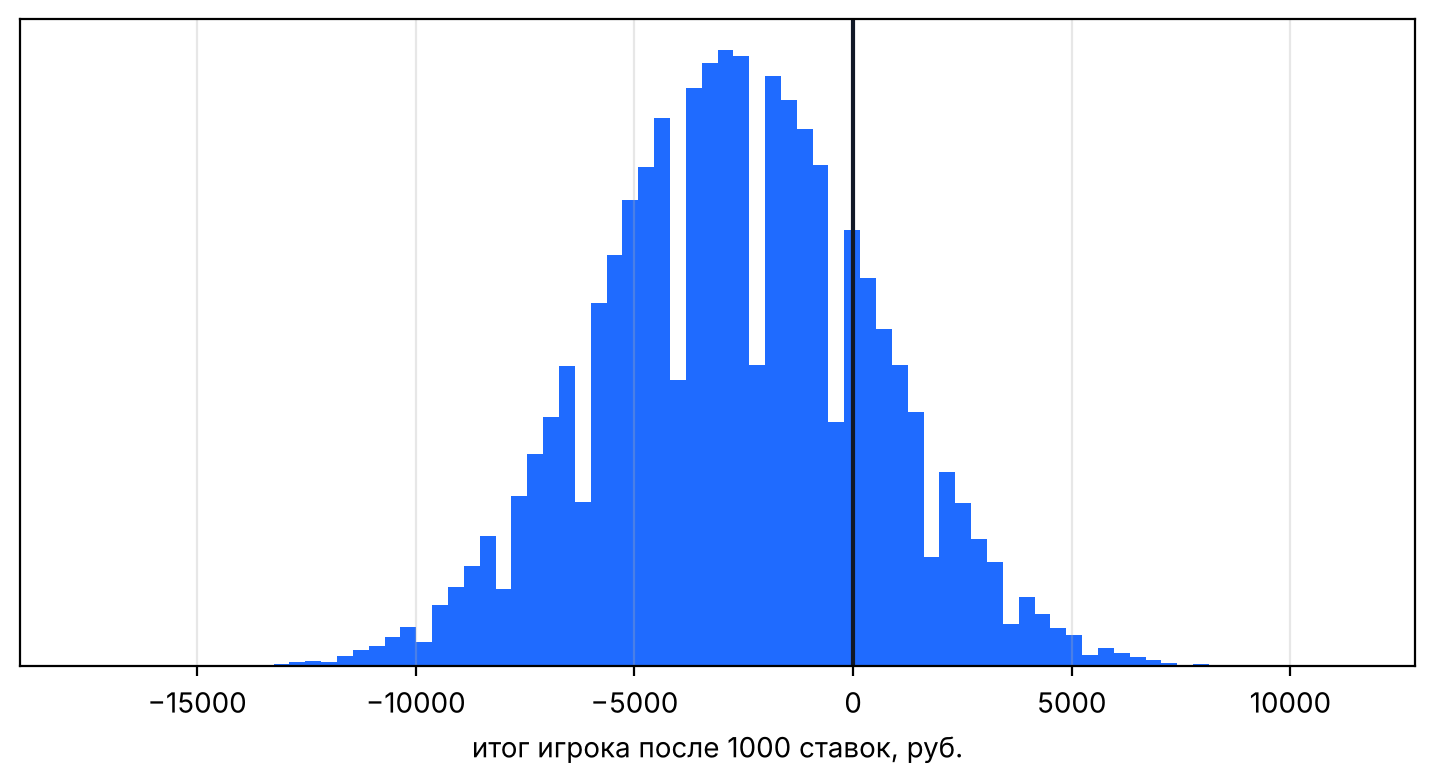

In [11]:
p = 18 / 37
players = 100 * (2 * rng.binomial(1000, p, size=200_000) - 1000)
print("Один игрок, 1000 ставок:")
print(f"  средний итог {players.mean():8.0f} руб., разброс {players.std():6.0f} руб., в плюсе {np.mean(players > 0):.1%} игроков")

n_bets = 10_000_000
casino = -100 * (2 * rng.binomial(n_bets, p, size=2_000) - n_bets)
print(f"Казино, 10 млн ставок: в среднем {casino.mean() / 1e6:.2f} млн руб., разброс {casino.std() / 1e6:.2f} млн руб.")
print(f"  доля «вечеров», когда казино в минусе: {np.mean(casino < 0)}")

plt.hist(players, bins=80, color=BLUE)
plt.axvline(0, color=DARK); plt.xlabel("итог игрока после 1000 ставок, руб."); plt.yticks([]); plt.show()

### 2.6. «Ошибка игрока»: после пяти чёрных

Смоделируем 2 000 000 запусков рулетки и посмотрим, как часто выпадает красное сразу после серии из пяти чёрных подряд.

In [12]:
spins = rng.choice(["к", "ч", "з"], p=[18 / 37, 18 / 37, 1 / 37], size=2_000_000)
black = spins == "ч"
after5 = np.convolve(black, np.ones(5, dtype=int), mode="valid")[:-1] == 5  # позиции i..i+4 — все чёрные
next_spin = spins[5:][after5]
print("серий «5 чёрных подряд»:", after5.sum())
print(f"красное сразу после серии: {(next_spin == 'к').mean():.4f}")
print(f"красное в любой момент:    {(spins == 'к').mean():.4f}   (18/37 = {18 / 37:.4f})")

серий «5 чёрных подряд»: 54281
красное сразу после серии: 0.4861
красное в любой момент:    0.4864   (18/37 = 0.4865)


Рулетка не помнит прошлого. ЗБЧ работает не «компенсацией», а **разбавлением**: лишние чёрные тонут в тысячах новых запусков.

### 2.7. Орлы обгоняют решки, а доля сходится

Разность «орлы − решки» растёт примерно как $\sqrt{n}$, а доля орлов приближается к $0{,}5$, потому что $\sqrt{n}/n=1/\sqrt{n}\to 0$.

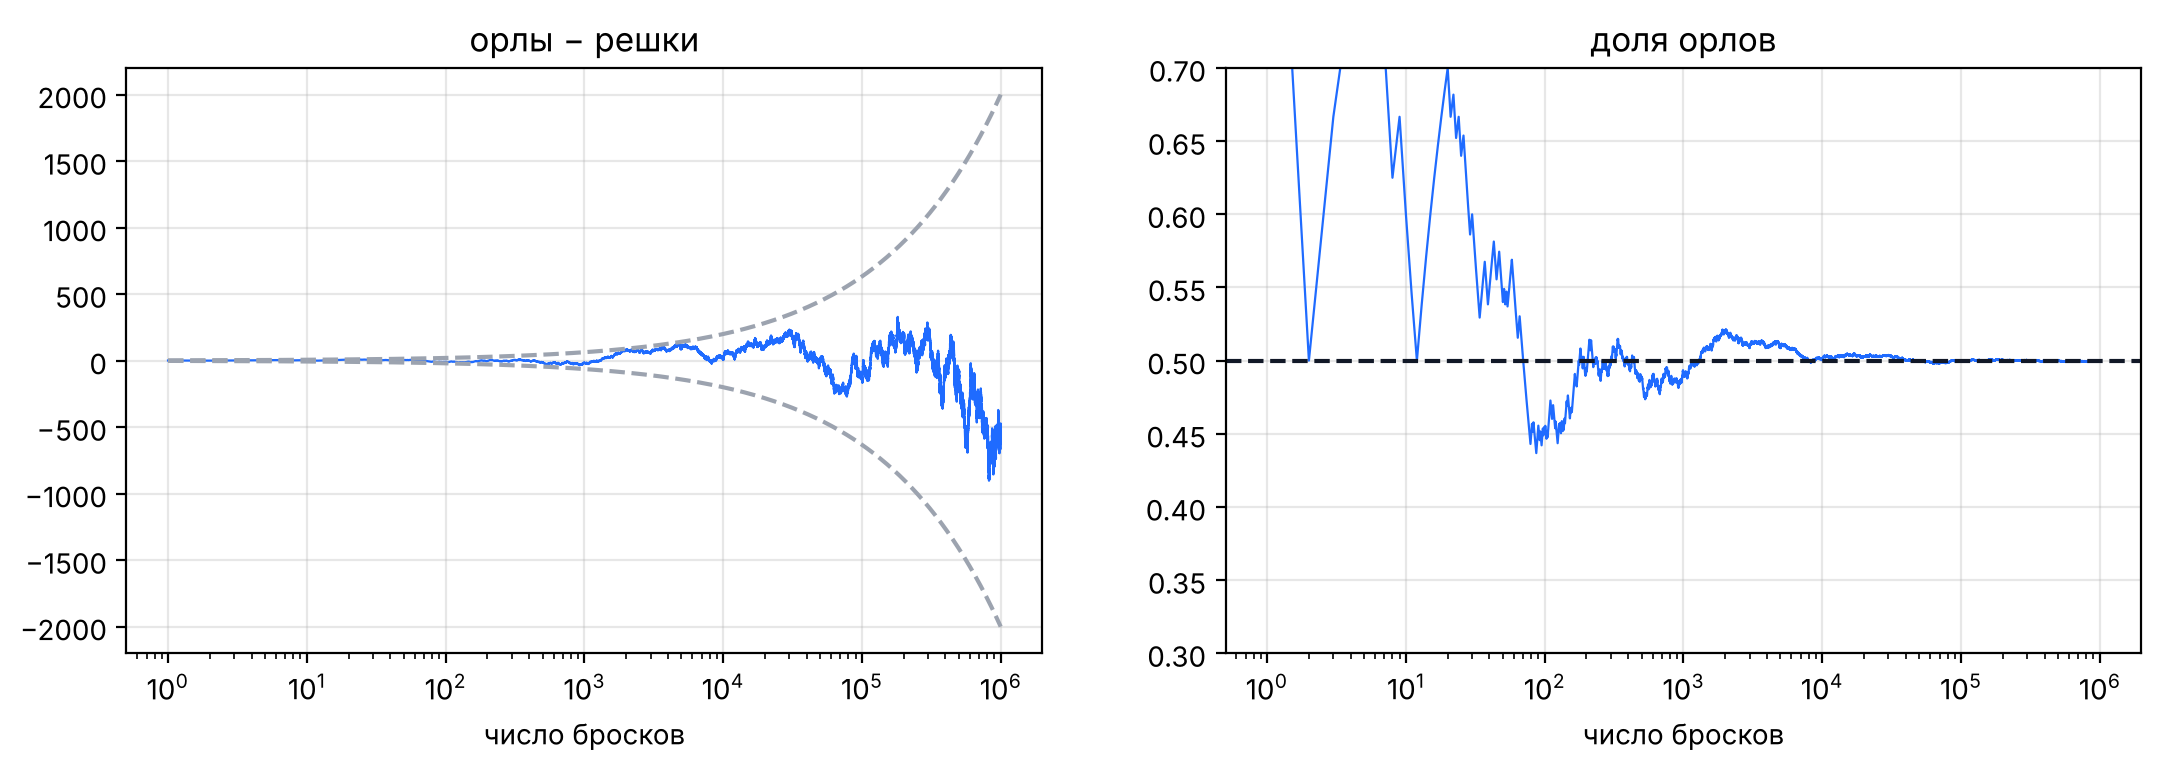

In [13]:
n = 1_000_000
flips = rng.integers(0, 2, n)
k = np.arange(1, n + 1)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(k, np.cumsum(2 * flips - 1), color=BLUE, lw=0.8)
axs[0].plot(k, 2 * np.sqrt(k), color=GRAY, ls="--"); axs[0].plot(k, -2 * np.sqrt(k), color=GRAY, ls="--")
axs[0].set_xscale("log"); axs[0].set_title("орлы − решки"); axs[0].set_xlabel("число бросков")
axs[1].plot(k, np.cumsum(flips) / k, color=BLUE, lw=0.8); axs[1].axhline(0.5, color=DARK, ls="--")
axs[1].set_xscale("log"); axs[1].set_ylim(0.3, 0.7); axs[1].set_title("доля орлов"); axs[1].set_xlabel("число бросков")
plt.show()

### 2.8. Когда ЗБЧ не работает: закон Коши

У закона Коши нет математического ожидания: изредка выпадают гигантские значения. Бегущее среднее не успокаивается никогда. Перезапустите ячейку несколько раз.

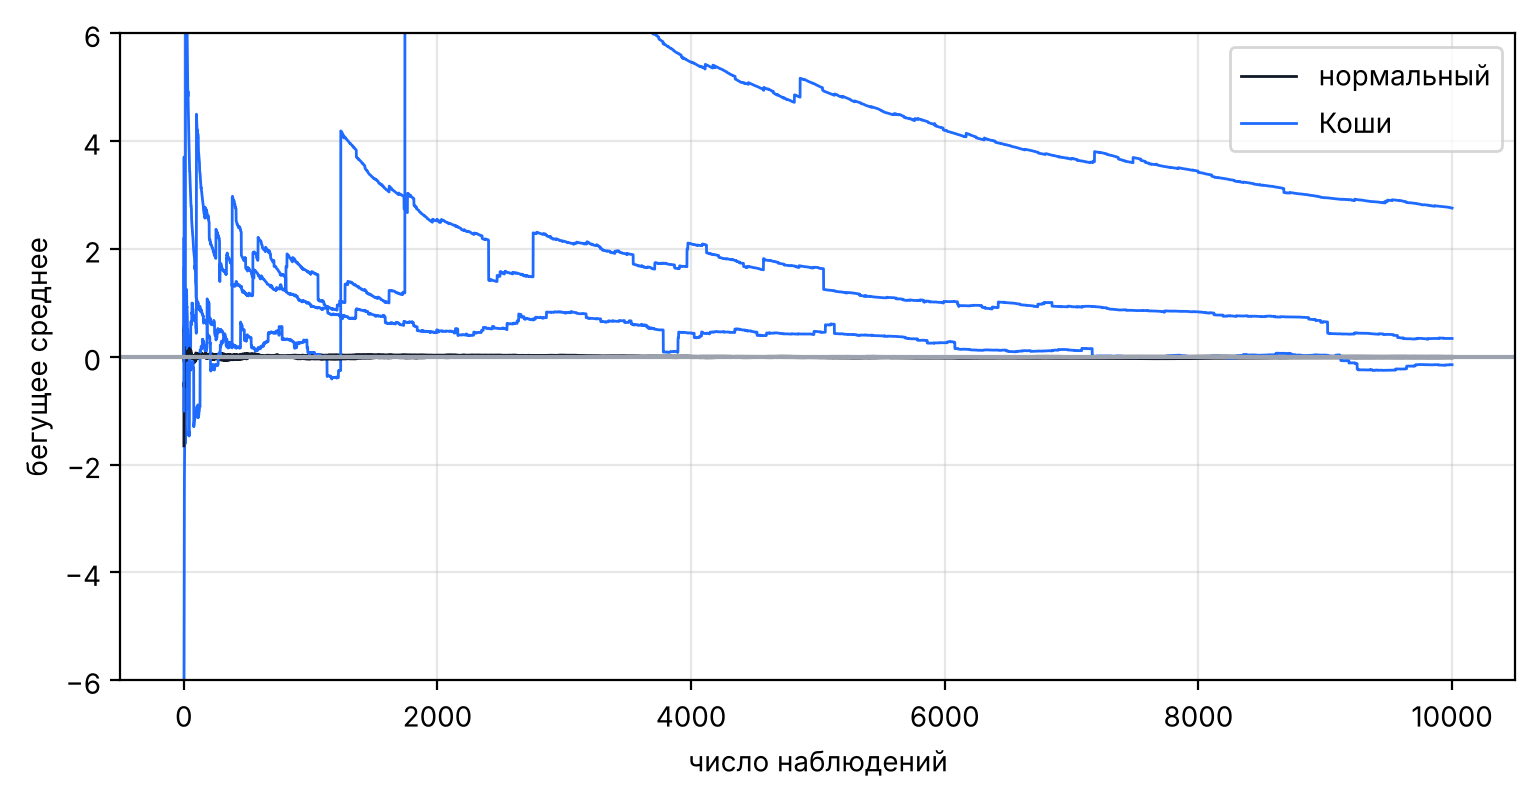

In [14]:
n = 10_000
k = np.arange(1, n + 1)
for i in range(3):
    plt.plot(k, np.cumsum(rng.normal(size=n)) / k, color=DARK, lw=1, label="нормальный" if i == 0 else None)
    plt.plot(k, np.cumsum(rng.standard_cauchy(n)) / k, color=BLUE, lw=1, label="Коши" if i == 0 else None)
plt.ylim(-6, 6); plt.axhline(0, color=GRAY); plt.xlabel("число наблюдений"); plt.ylabel("бегущее среднее"); plt.legend(); plt.show()

### 2.9. Рейтинг районов

3 000 районов разного размера, частота редкой болезни **везде одинаковая**: 60 случаев на 100 тыс. жителей. Отметим 30 «самых больных» и 30 «самых здоровых» районов и нарисуем коридор $60\pm 2\sigma/\sqrt{n}$.

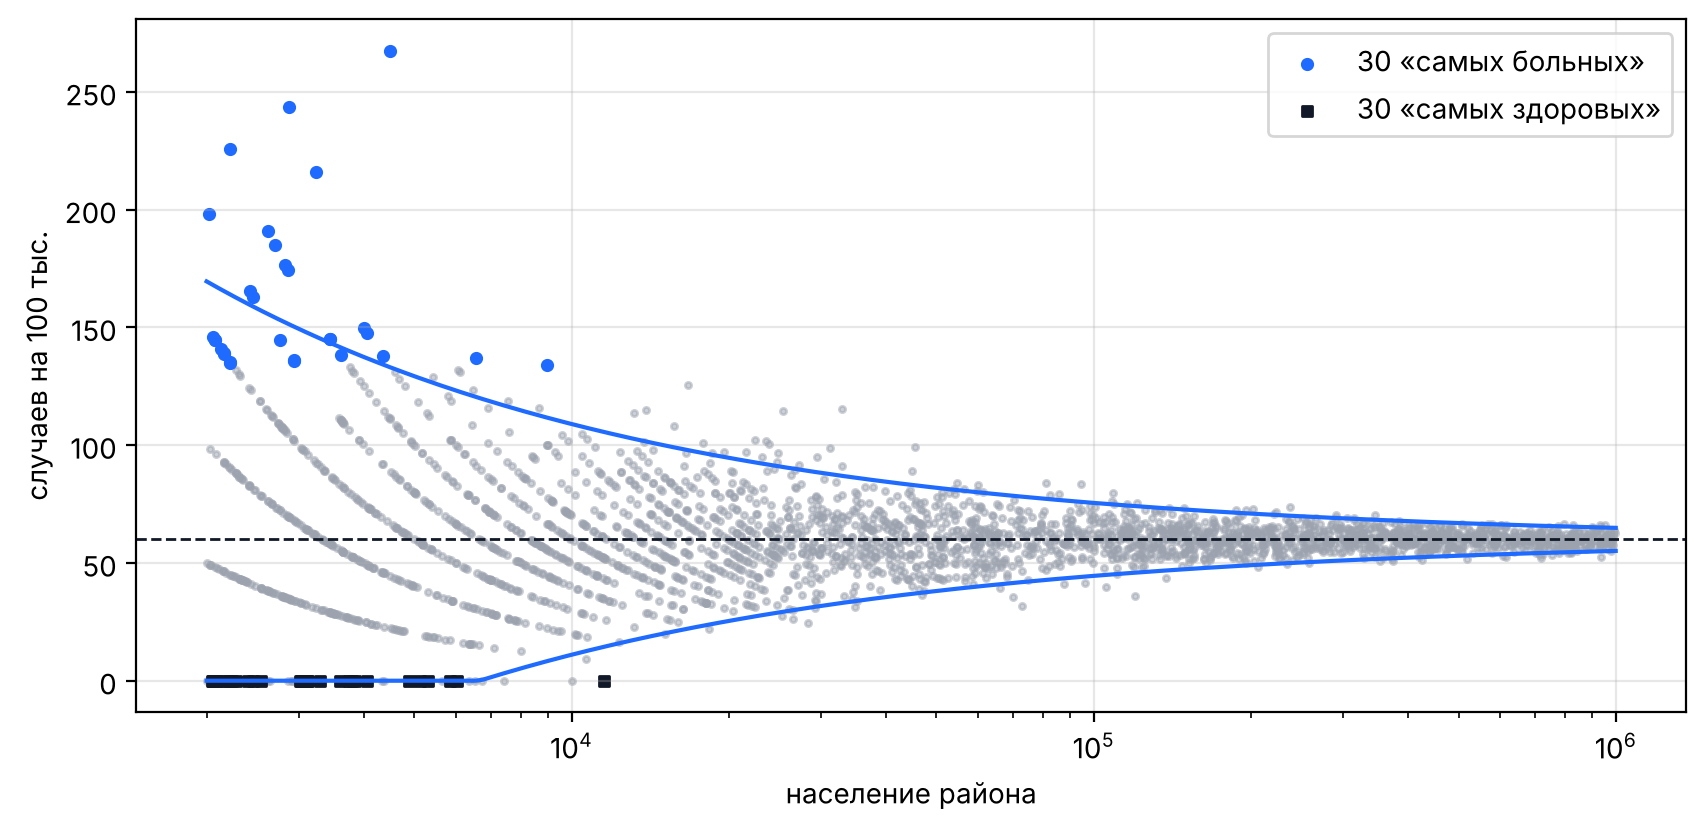

медианное население самых больных:  2799
медианное население самых здоровых: 3088
медианное население всех районов:   44265
внутри коридора: 95.8% районов


In [15]:
P = 60e-5
pop = np.exp(rng.uniform(np.log(2e3), np.log(1e6), 3000)).astype(int)
rate = rng.binomial(pop, P) / pop * 1e5
order = np.argsort(rate)
lo, hi = order[:30], order[-30:]

x = np.geomspace(2e3, 1e6, 200)
se = np.sqrt(P * (1 - P) / x) * 1e5
plt.figure(figsize=(10, 4.5))
plt.scatter(pop, rate, s=5, color=GRAY, alpha=0.5)
plt.scatter(pop[hi], rate[hi], s=14, color=BLUE, label="30 «самых больных»")
plt.scatter(pop[lo], rate[lo], s=14, color=DARK, marker="s", label="30 «самых здоровых»")
plt.plot(x, 60 + 2 * se, color=BLUE); plt.plot(x, np.maximum(60 - 2 * se, 0), color=BLUE)
plt.axhline(60, color=DARK, ls="--", lw=1)
plt.xscale("log"); plt.xlabel("население района"); plt.ylabel("случаев на 100 тыс."); plt.legend(); plt.show()

print("медианное население самых больных: ", int(np.median(pop[hi])))
print("медианное население самых здоровых:", int(np.median(pop[lo])))
print("медианное население всех районов:  ", int(np.median(pop)))
inside = np.abs(rate - 60) <= 2 * np.sqrt(P * (1 - P) / pop) * 1e5
print(f"внутри коридора: {inside.mean():.1%} районов")

---
## 3. Центральная предельная теорема

Сумма $S_n=X_1+\ldots+X_n$ независимых одинаково распределённых величин с $E(X_i)=a$, $\mathrm{Var}(X_i)=\sigma^2$ при больших $n$ распределена приближённо нормально:
$$S_n\approx N(na,\ n\sigma^2),\qquad P(\alpha<S_n<\beta)\approx\Phi\left(\frac{\beta-na}{\sigma\sqrt n}\right)-\Phi\left(\frac{\alpha-na}{\sigma\sqrt n}\right).$$
Для среднего: $\bar X\approx N(a,\sigma^2/n)$ и $P(|\bar X-a|<\delta)\approx 2\Phi\left(\dfrac{\delta\sqrt n}{\sigma}\right)$.

### 3.1. Доска Гальтона

Шарик проходит `rows` рядов гвоздей и на каждом отскакивает вправо с вероятностью $1/2$. Номер ячейки — число отскоков вправо.

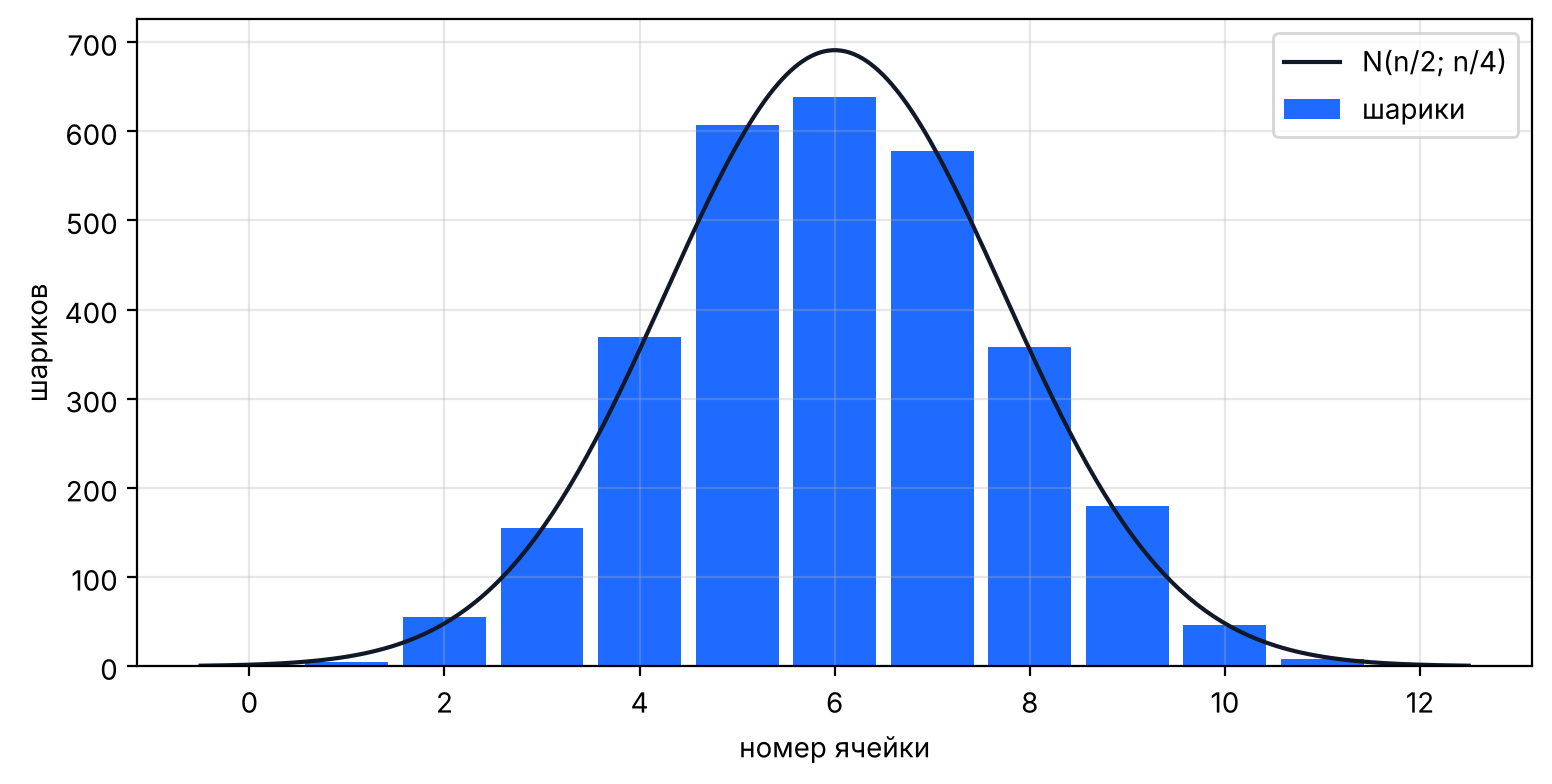

interactive(children=(IntSlider(value=12, description='рядов', max=60, min=1), IntSlider(value=3000, descripti…

In [16]:
def galton(rows=12, balls=3000):
    cells = (rng.random((balls, rows)) < 0.5).sum(axis=1)
    cnt = np.bincount(cells, minlength=rows + 1)
    plt.bar(np.arange(rows + 1), cnt, color=BLUE, width=0.85, label="шарики")
    z = np.linspace(-0.5, rows + 0.5, 300)
    plt.plot(z, balls * stats.norm.pdf(z, rows / 2, np.sqrt(rows / 4)), color=DARK, label="N(n/2; n/4)")
    plt.xlabel("номер ячейки"); plt.ylabel("шариков"); plt.legend(); plt.show()

galton()
if HAS_WIDGETS:
    interact(galton, rows=IntSlider(12, 1, 60, description="рядов"), balls=IntSlider(3000, 100, 50_000, step=100, description="шариков"));

### 3.2. Сумма кубиков

Ряд распределения суммы $n$ кубиков считаем точно (свёрткой), без симуляции. Чёрная кривая — нормальный закон с $E=3{,}5n$ и $\mathrm{Var}=\frac{35}{12}n$.

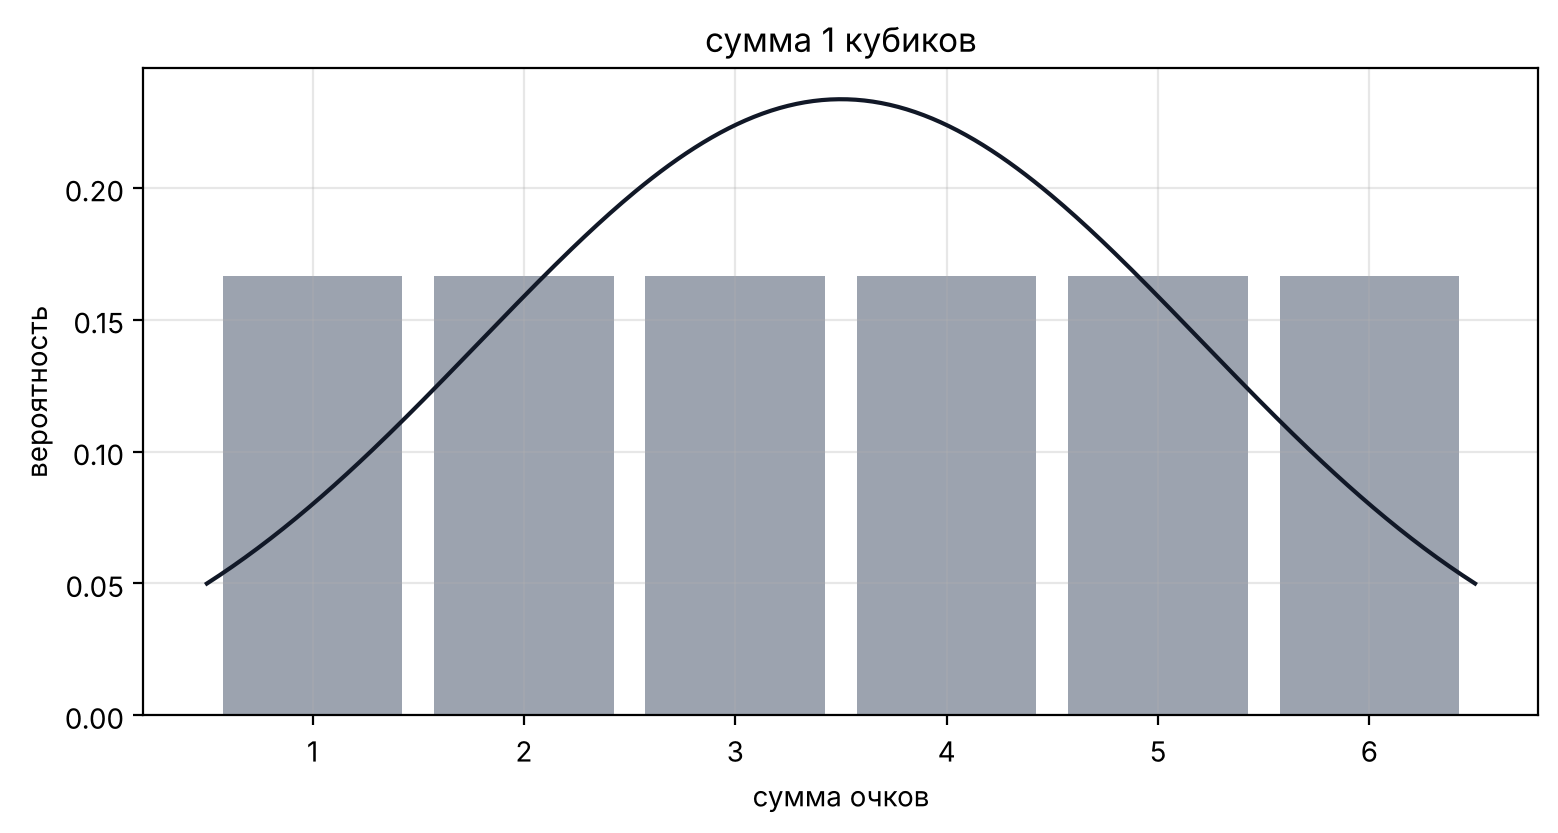

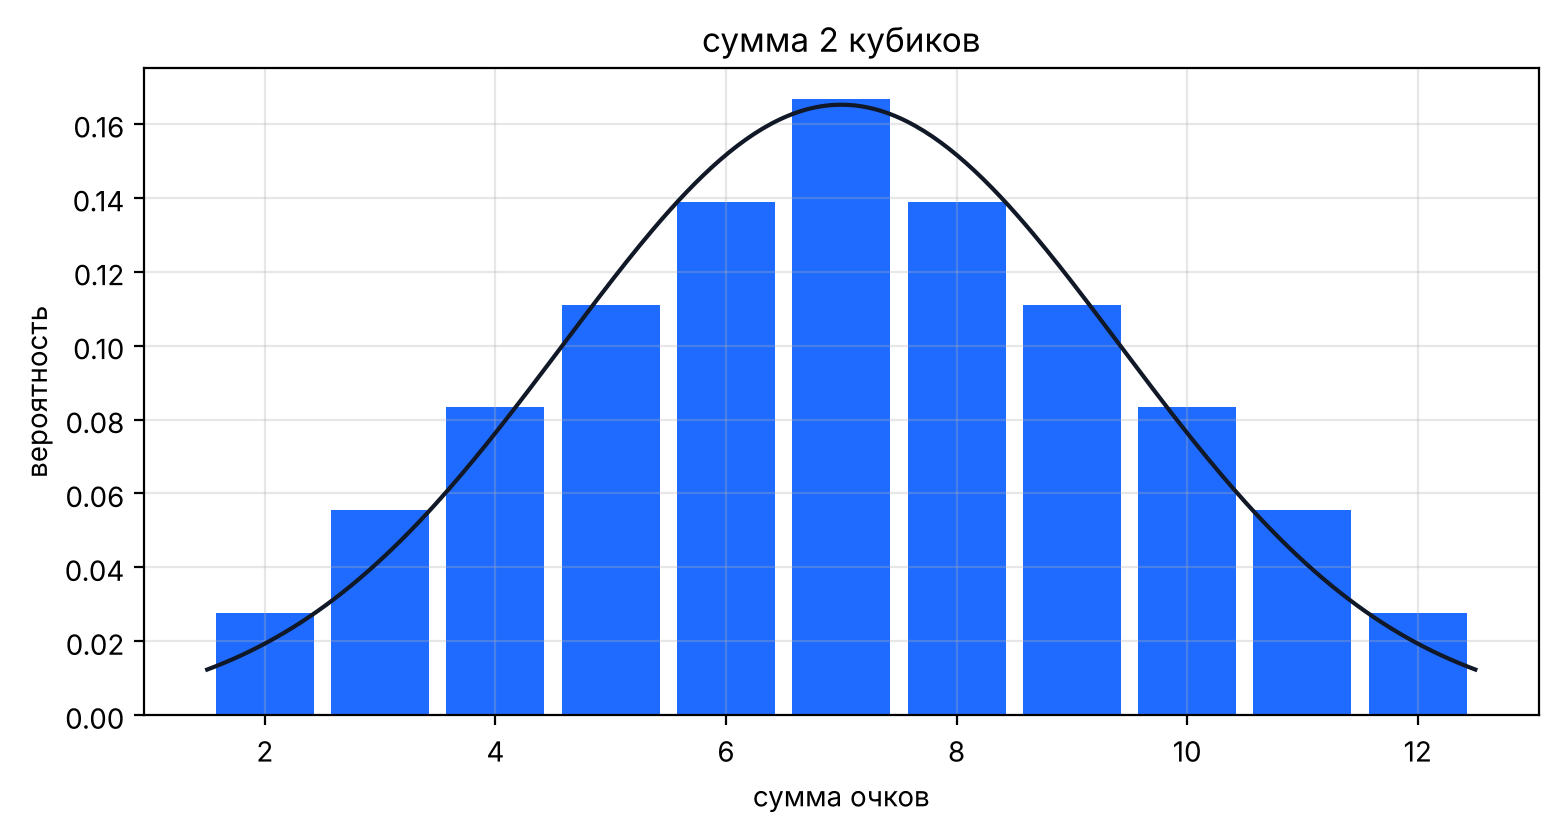

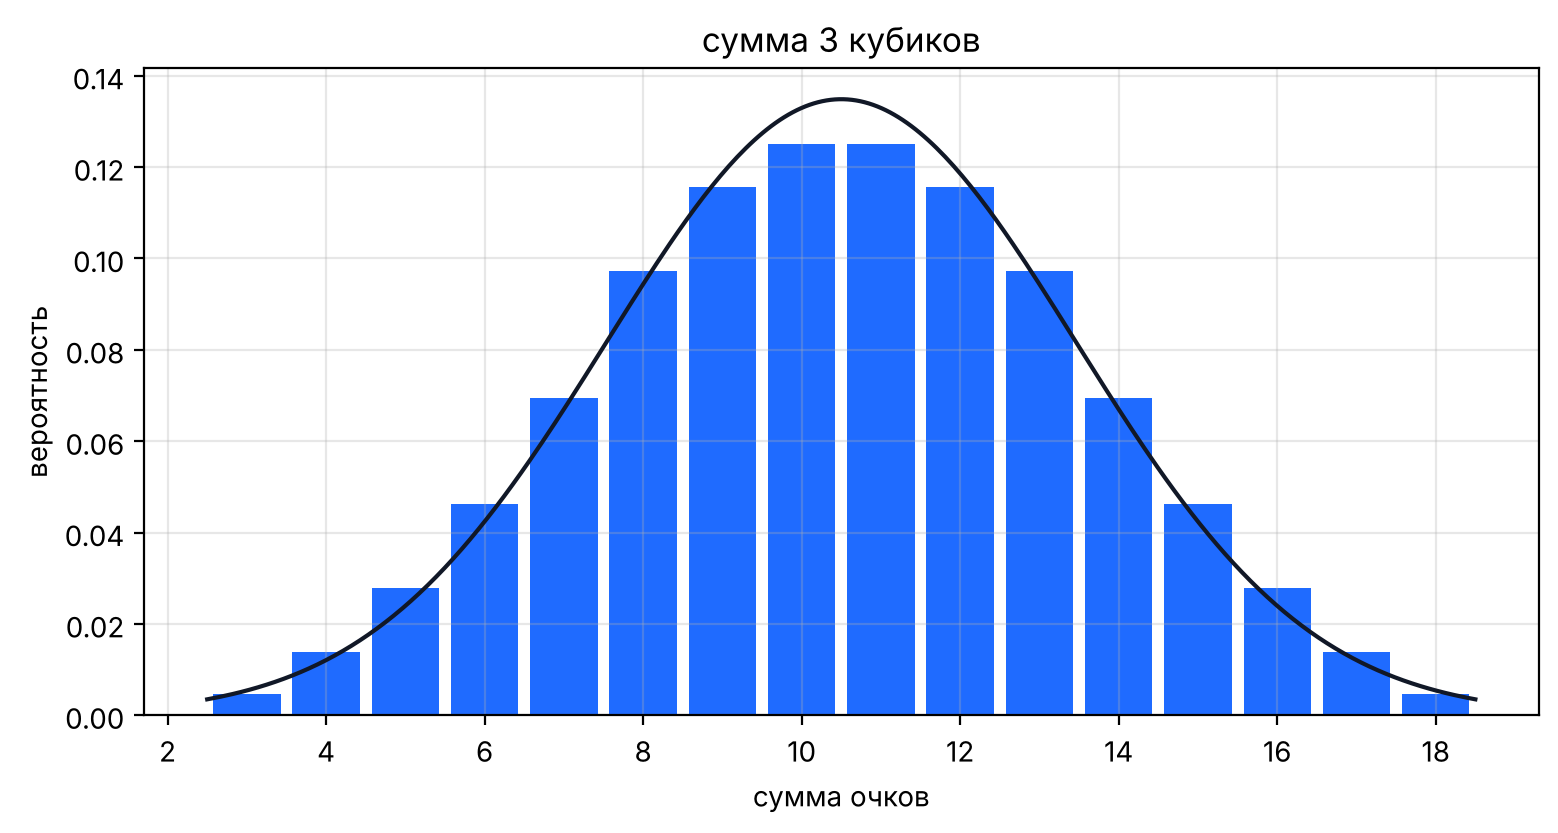

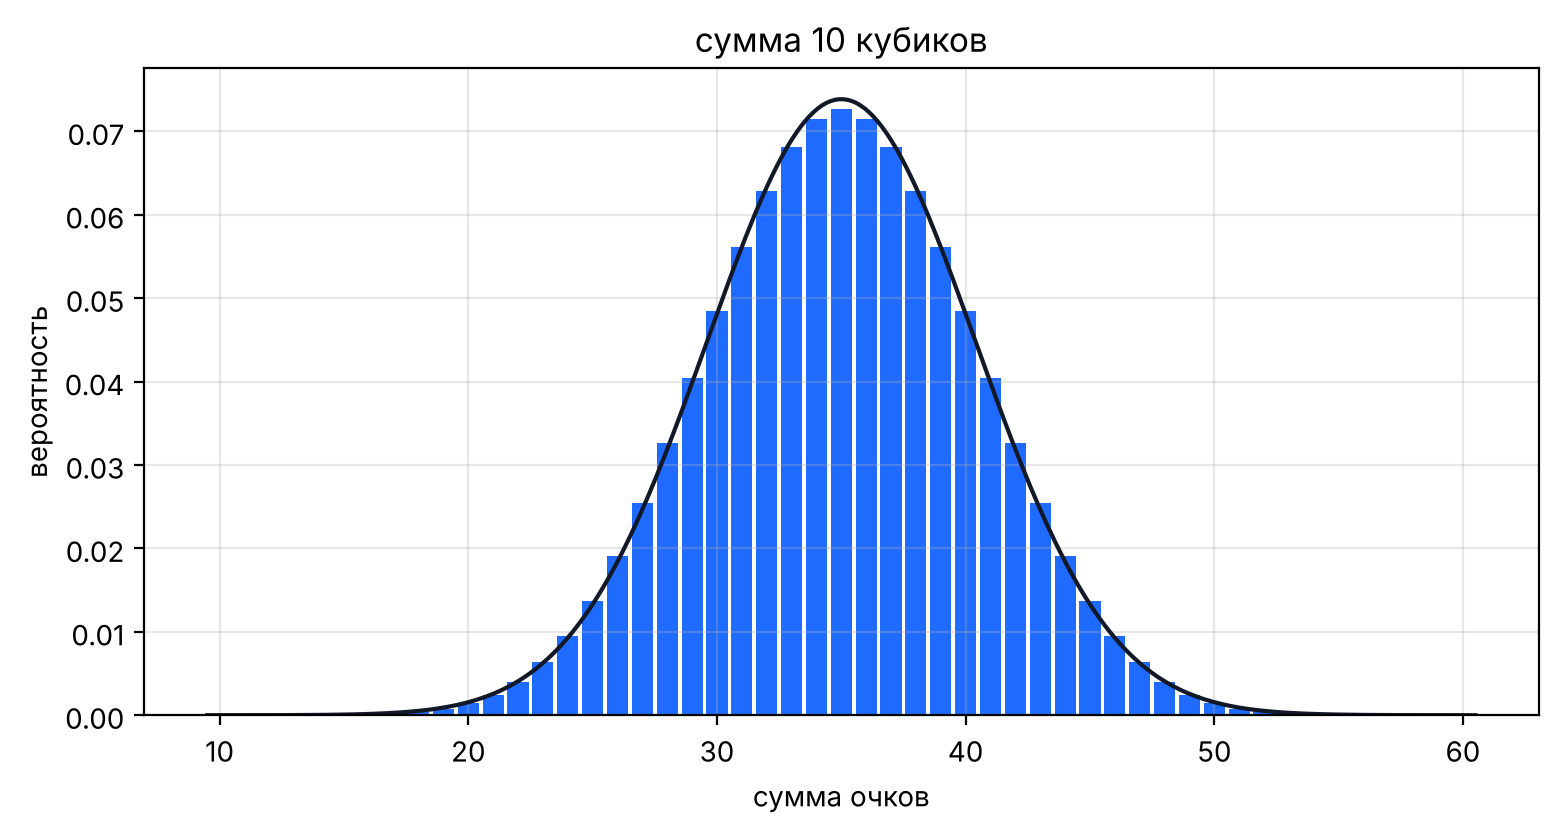

In [17]:
def dice_sum(n=3):
    die = np.full(6, 1 / 6)
    pmf = die.copy()
    for _ in range(n - 1):
        pmf = np.convolve(pmf, die)
    xs = np.arange(n, 6 * n + 1)
    plt.bar(xs, pmf, color=BLUE if n > 1 else GRAY, width=0.85)
    z = np.linspace(n - 0.5, 6 * n + 0.5, 300)
    plt.plot(z, stats.norm.pdf(z, 3.5 * n, np.sqrt(35 / 12 * n)), color=DARK)
    plt.title(f"сумма {n} кубиков"); plt.xlabel("сумма очков"); plt.ylabel("вероятность"); plt.show()

for n in [1, 2, 3, 10]:
    dice_sum(n)

In [18]:
if HAS_WIDGETS:
    interact(dice_sum, n=IntSlider(3, 1, 40, description="кубиков"));

interactive(children=(IntSlider(value=3, description='кубиков', max=40, min=1), Output()), _dom_classes=('widg…

### 3.3. Колокол из чего угодно

Выберите исходный закон и число слагаемых $n$. Слева — гистограмма самих данных, справа — гистограмма 50 000 средних по $n$ наблюдений и нормальная кривая $N(a,\sigma^2/n)$.

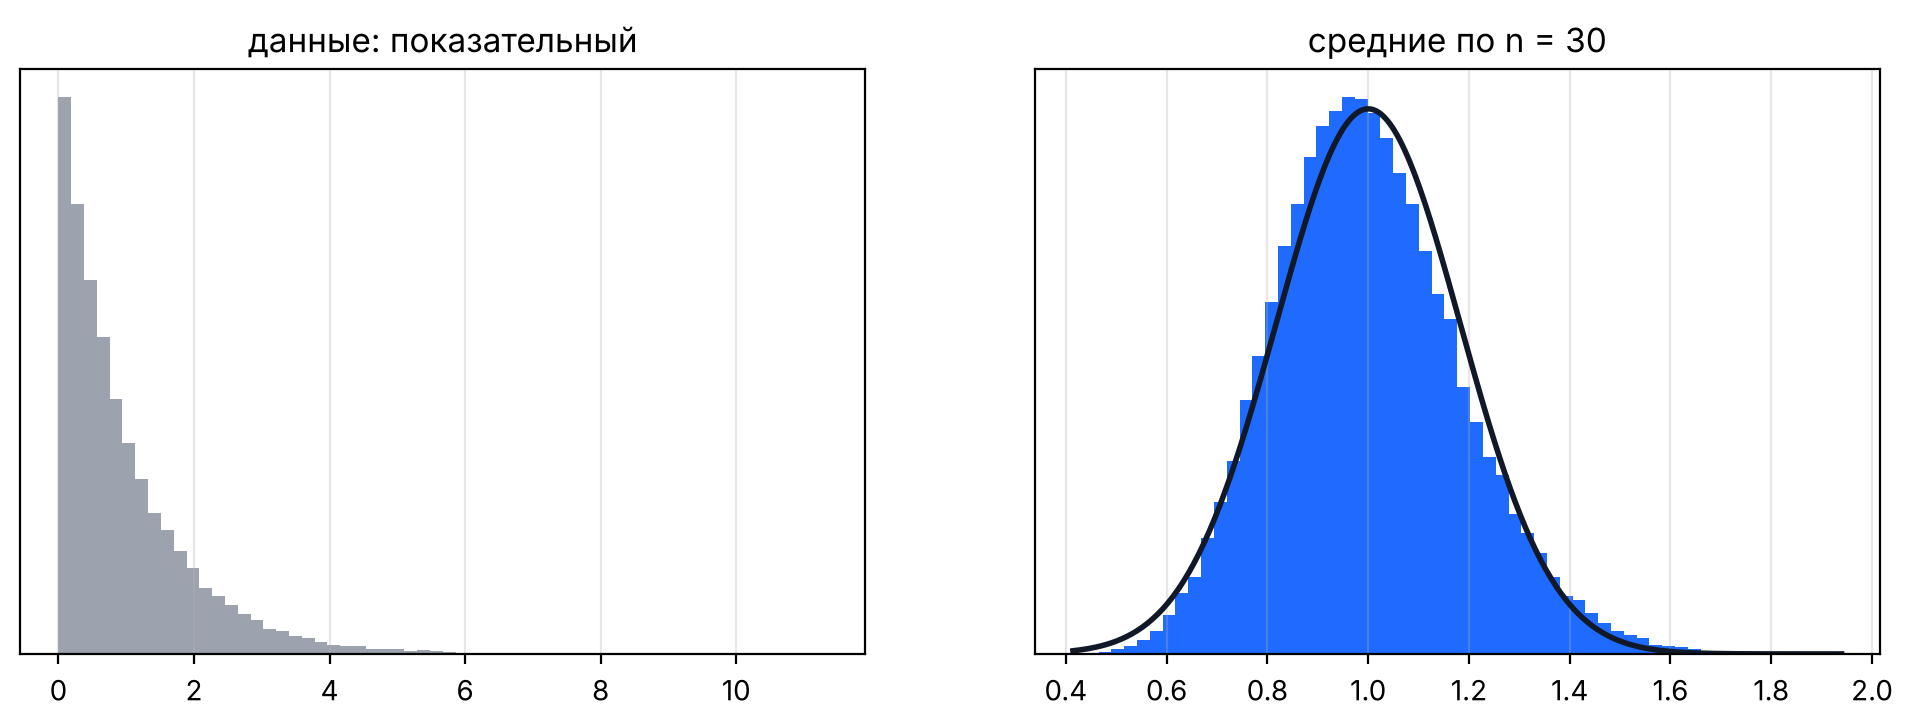

interactive(children=(Dropdown(description='закон', index=1, options=('равномерный', 'показательный', 'редкое …

In [19]:
LAWS = {
    "равномерный": (lambda size: rng.uniform(0, 1, size), 0.5, np.sqrt(1 / 12)),
    "показательный": (lambda size: rng.exponential(1, size), 1, 1),
    "редкое событие (1 с вер. 0,1)": (lambda size: (rng.random(size) < 0.1).astype(float), 0.1, 0.3),
    "«две горки»": (lambda size: np.where(rng.random(size) < 0.5, rng.normal(-2, 0.5, size), rng.normal(2, 0.5, size)),
                    0, np.sqrt(4.25)),
    "кубик": (lambda size: rng.integers(1, 7, size).astype(float), 3.5, np.sqrt(35 / 12)),
}

def clt_demo(law="показательный", n=5):
    gen, a, sigma = LAWS[law]
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
    axs[0].hist(gen(50_000), bins=60, color=GRAY, density=True); axs[0].set_title(f"данные: {law}")
    means = gen((50_000, n)).mean(axis=1)
    axs[1].hist(means, bins=60, color=BLUE, density=True)
    z = np.linspace(means.min(), means.max(), 300)
    axs[1].plot(z, stats.norm.pdf(z, a, sigma / np.sqrt(n)), color=DARK, lw=2)
    axs[1].set_title(f"средние по n = {n}")
    for ax in axs:
        ax.set_yticks([])
    plt.show()

clt_demo("показательный", 30)
if HAS_WIDGETS:
    interact(clt_demo, law=Dropdown(options=list(LAWS), value="показательный", description="закон"),
             n=IntSlider(5, 1, 200, description="n"));

У редкого события при малых $n$ средние принимают лишь несколько значений и сильно перекошены. Колокол появляется, только когда $np$ становится порядка 10.

### 3.4. Теорема Муавра — Лапласа как частный случай ЦПТ

Число успехов $m$ — сумма $n$ индикаторов, поэтому $m\approx N(np,\ npq)$. Подвигайте $n$ и $p$: при малом $np$ приближение плохое.

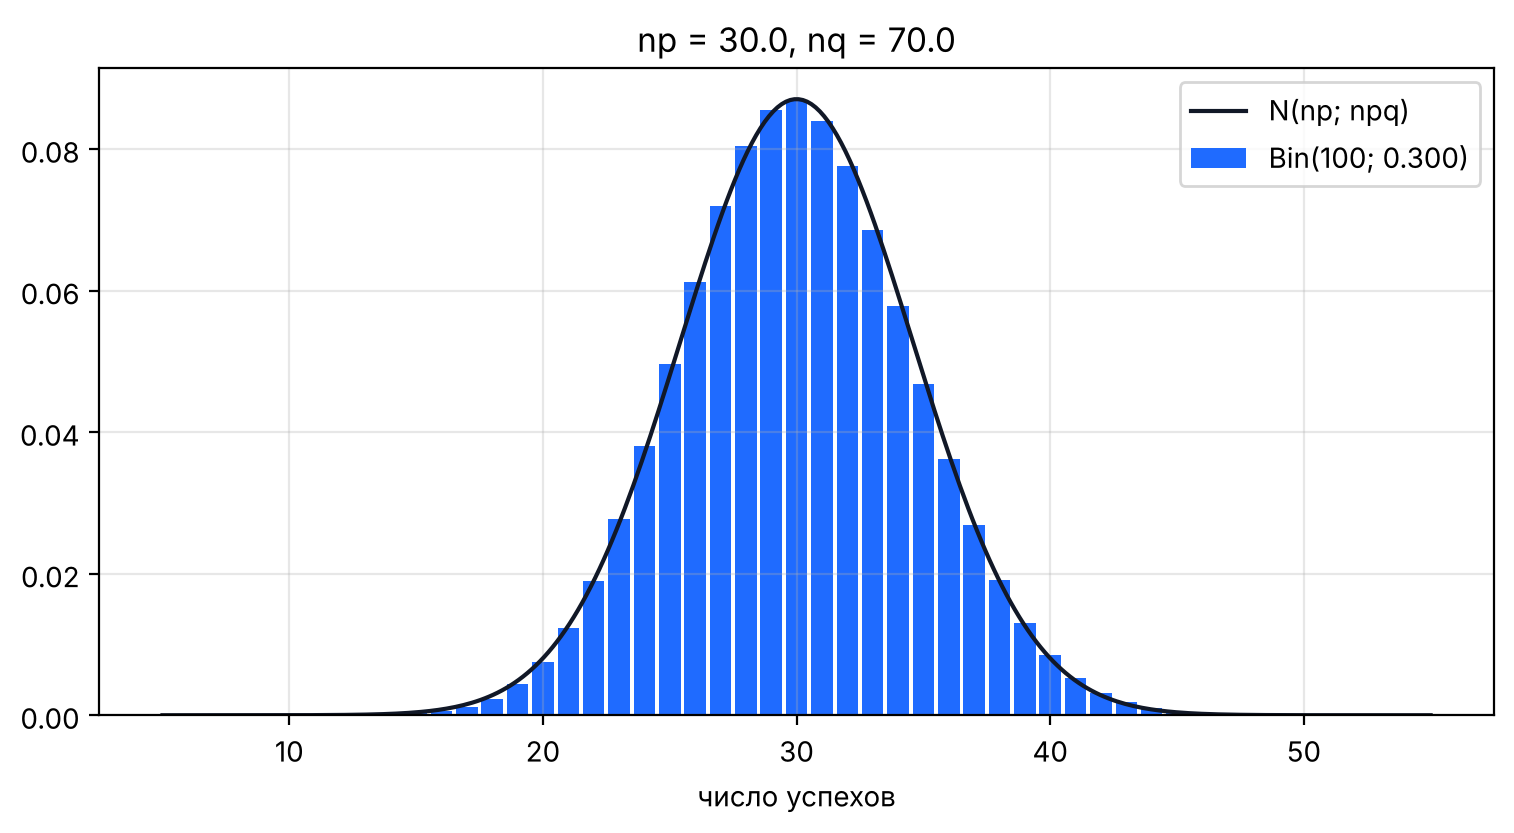

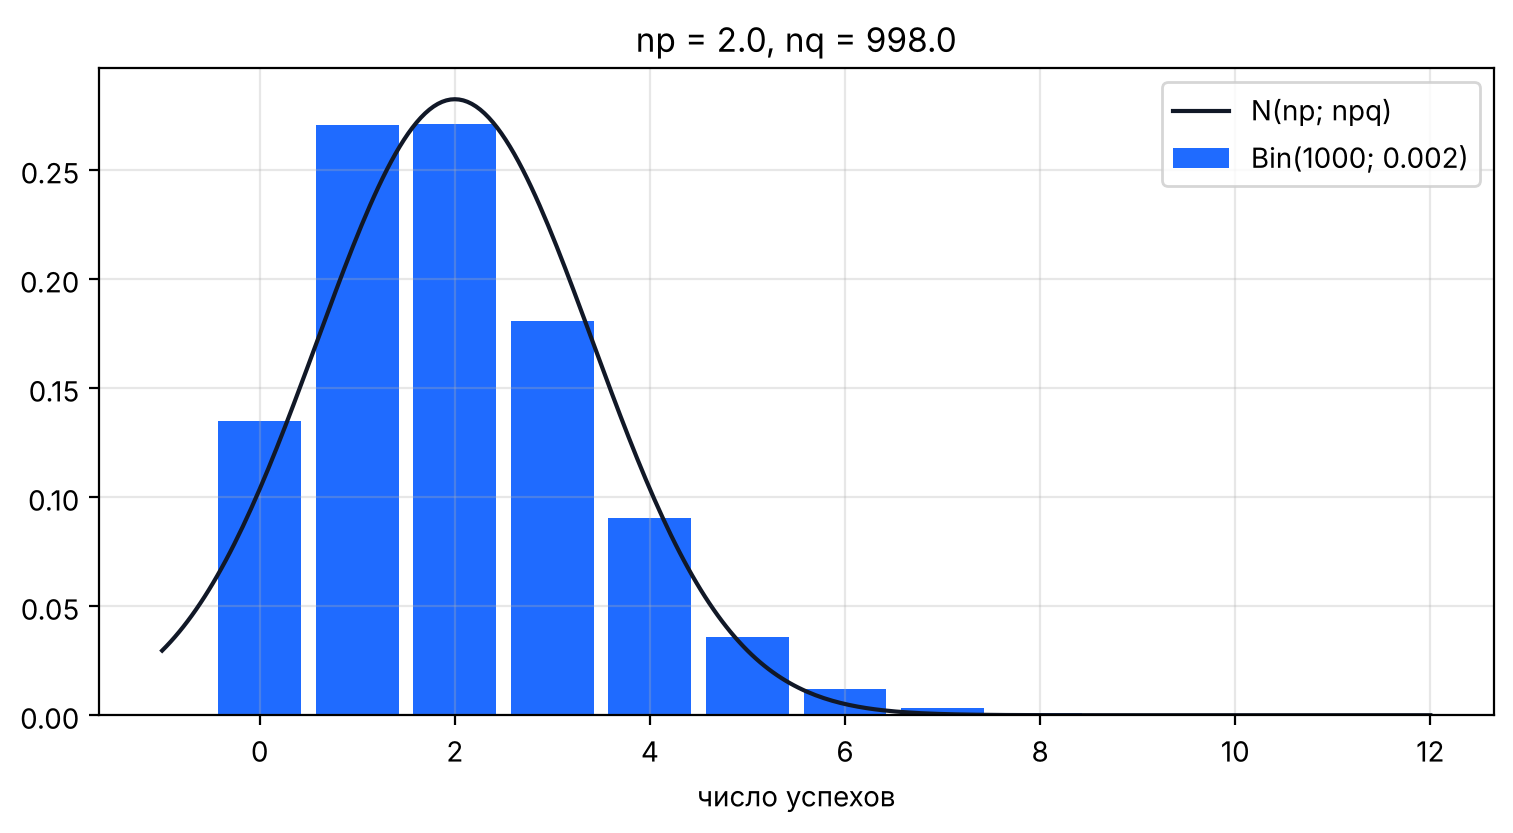

interactive(children=(IntSlider(value=100, description='n', max=2000, min=5), FloatSlider(value=0.3, descripti…

In [20]:
def moivre(n=100, p=0.3):
    b = stats.binom(n, p)
    lo = max(0, int(b.mean() - 5 * b.std()) - 1); hi = int(b.mean() + 5 * b.std()) + 2
    ks = np.arange(lo, min(n, hi) + 1)
    plt.bar(ks, b.pmf(ks), color=BLUE, width=0.85, label=f"Bin({n}; {p:.3f})")
    z = np.linspace(ks[0] - 1, ks[-1] + 1, 300)
    plt.plot(z, stats.norm.pdf(z, n * p, np.sqrt(n * p * (1 - p))), color=DARK, label="N(np; npq)")
    plt.title(f"np = {n * p:.1f}, nq = {n * (1 - p):.1f}"); plt.xlabel("число успехов"); plt.legend(); plt.show()

moivre(100, 0.3)
moivre(1000, 0.002)
if HAS_WIDGETS:
    interact(moivre, n=IntSlider(100, 5, 2000, description="n"),
             p=FloatSlider(value=0.3, min=0.001, max=0.999, step=0.001, readout_format=".3f", description="p"));

### 3.5. ЗБЧ и ЦПТ на одной картинке

Слева — средние по $n$ ожиданиям автобуса: они сжимаются к $a=12$ (ЗБЧ). Справа — те же средние, приведённые к виду $(\bar X-a)/(\sigma/\sqrt n)$: все $n$ дают один и тот же колокол $N(0;1)$ (ЦПТ).

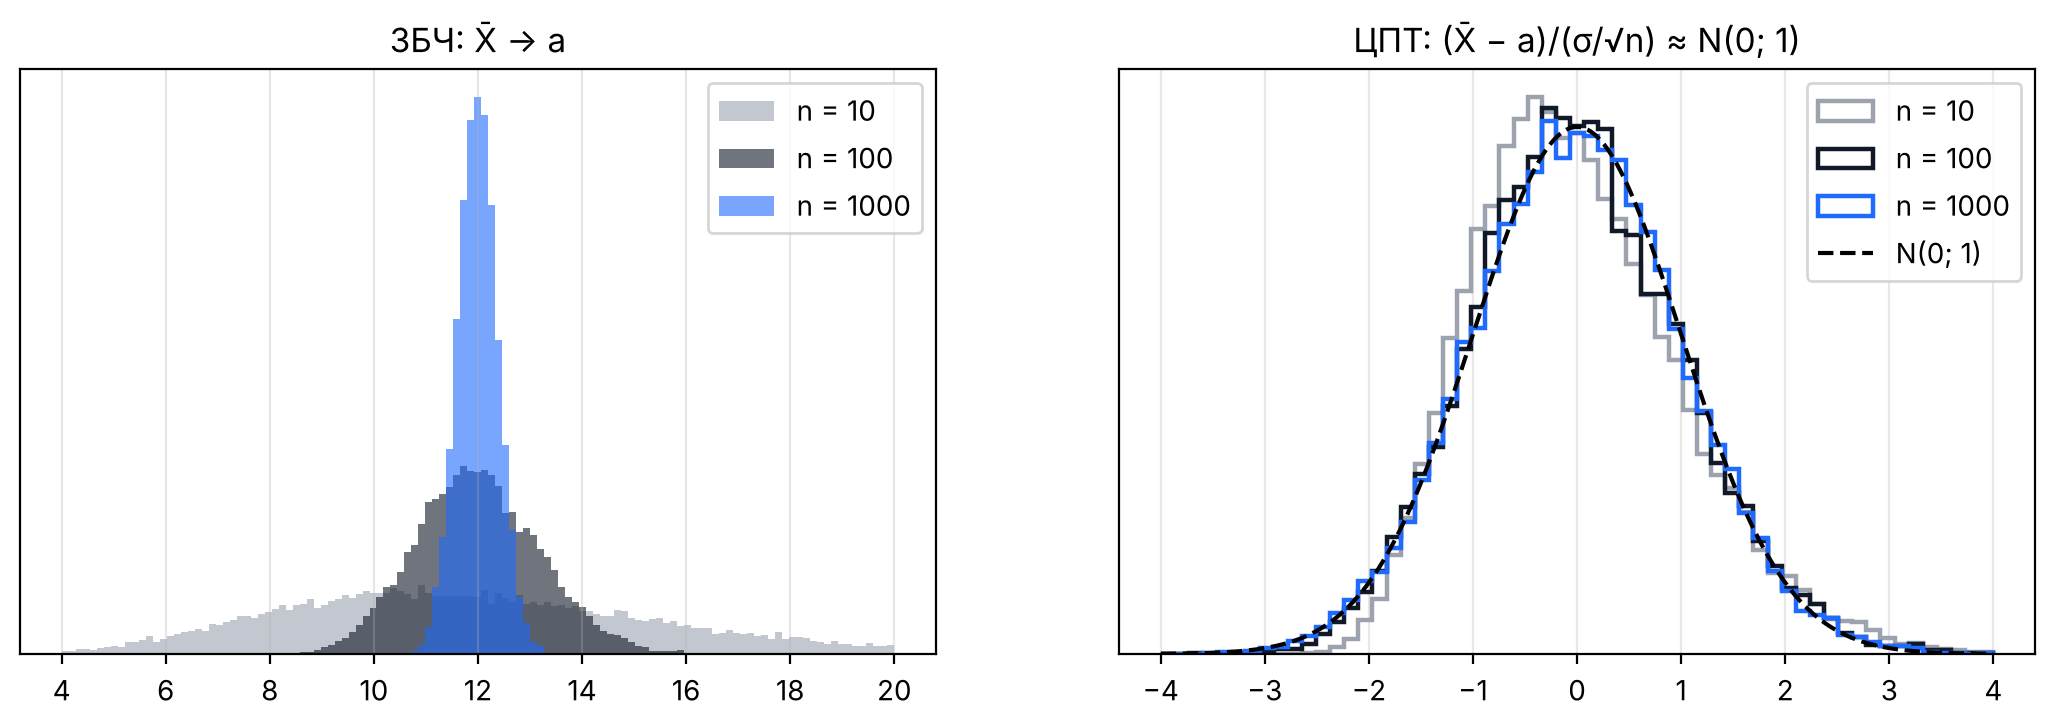

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for n, c in [(10, GRAY), (100, DARK), (1000, BLUE)]:
    m = rng.exponential(12, size=(20_000, n)).mean(axis=1)
    axs[0].hist(m, bins=np.linspace(4, 20, 120), color=c, alpha=0.6, density=True, label=f"n = {n}")
    axs[1].hist((m - 12) / (12 / np.sqrt(n)), bins=np.linspace(-4, 4, 60), histtype="step", lw=1.6, color=c,
                density=True, label=f"n = {n}")
z = np.linspace(-4, 4, 200)
axs[1].plot(z, stats.norm.pdf(z), "k--", label="N(0; 1)")
axs[0].set_title("ЗБЧ: X̄ → a"); axs[1].set_title("ЦПТ: (X̄ − a)/(σ/√n) ≈ N(0; 1)")
for ax in axs:
    ax.legend(); ax.set_yticks([])
plt.show()

---
## 4. Задачи лекции: проверяем симуляцией

### 4.1. Средний чек

Средний чек $a=400$ руб., $\sigma=250$ руб. Чеки перекошены вправо, поэтому моделируем их логнормальным законом с такими $E$ и $\sigma$. Какова вероятность, что средний чек за 100 покупок будет не меньше 450 руб.?

ЦПТ: $\sigma_{\bar X}=250/\sqrt{100}=25$, $P(\bar X\ge 450)\approx 0{,}5-\Phi(2)\approx 0{,}023$.

E и σ одного чека: 400.0 250.0


симуляция: P(X̄ ≥ 450) ≈ 0.0285
ЦПТ:       0,5 − Φ(2)  = 0.0228
Чебышёв:   P(|X̄ − 400| ≥ 50) ≤ 0.25,  симуляция: 0.0453


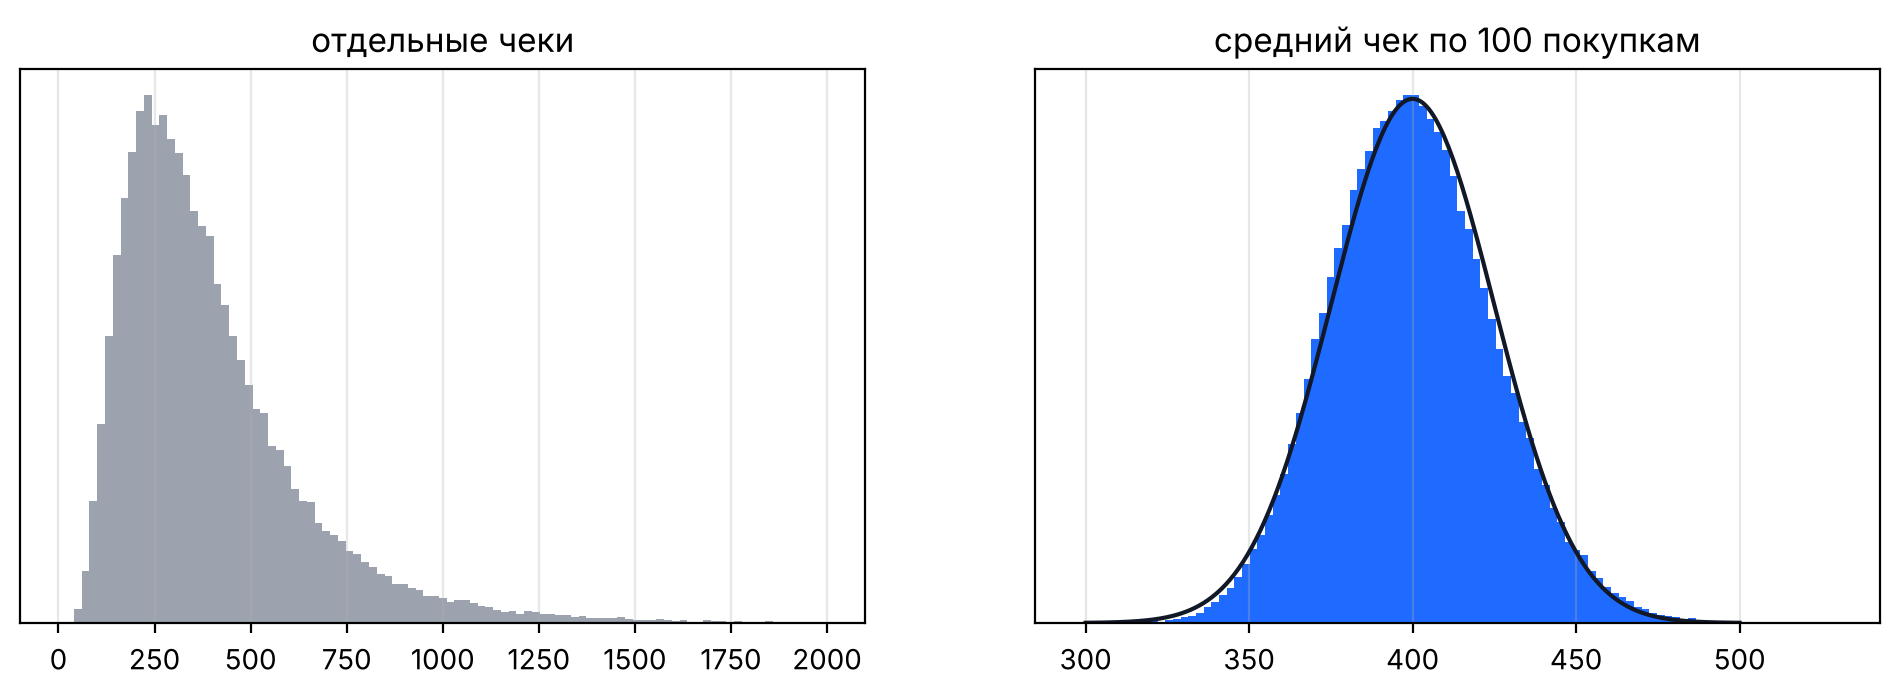

In [22]:
a, sigma, n = 400, 250, 100
s2 = np.log(1 + sigma**2 / a**2)                       # параметры логнормального закона с нужными E и σ
checks = stats.lognorm(s=np.sqrt(s2), scale=a / np.exp(s2 / 2))
print("E и σ одного чека:", round(checks.mean(), 1), round(checks.std(), 1))

means = checks.rvs(size=(200_000, n), random_state=1).mean(axis=1)
print(f"симуляция: P(X̄ ≥ 450) ≈ {(means >= 450).mean():.4f}")
print(f"ЦПТ:       0,5 − Φ(2)  = {0.5 - Phi(2):.4f}")
print(f"Чебышёв:   P(|X̄ − 400| ≥ 50) ≤ {25**2 / 50**2:.2f},  симуляция: {(np.abs(means - 400) >= 50).mean():.4f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(checks.rvs(size=50_000, random_state=2), bins=np.linspace(0, 2000, 100), color=GRAY); axs[0].set_title("отдельные чеки")
axs[1].hist(means, bins=100, color=BLUE, density=True); axs[1].set_title("средний чек по 100 покупкам")
z = np.linspace(300, 500, 300); axs[1].plot(z, stats.norm.pdf(z, a, sigma / np.sqrt(n)), color=DARK)
for ax in axs:
    ax.set_yticks([])
plt.show()

### 4.2. Всхожесть семян

Вероятность всхожести семени $0{,}9$, посеяли 400 семян. Найдём вероятность того, что доля взошедших отличается от $0{,}9$ меньше чем на $0{,}03$.

Чебышёв: не меньше $0{,}75$. ЦПТ: $2\Phi(0{,}03/0{,}015)=2\Phi(2)\approx 0{,}954$.

In [23]:
n, p = 400, 0.9
freq = rng.binomial(n, p, size=500_000) / n
print(f"симуляция:     {(np.abs(freq - p) < 0.03).mean():.4f}")
print(f"ЦПТ:           {2 * Phi(0.03 / np.sqrt(p * (1 - p) / n)):.4f}")
print(f"точно (Bin):   {stats.binom(n, p).cdf(371) - stats.binom(n, p).cdf(348):.4f}   — m от 349 до 371")
print(f"Чебышёв:   ≥ {1 - p * (1 - p) / (n * 0.03**2):.2f}")

симуляция:     0.9457
ЦПТ:           0.9545
точно (Bin):   0.9454   — m от 349 до 371
Чебышёв:   ≥ 0.75


### 4.3. Сумма округлений

Бухгалтер округляет 100 сумм до целых рублей. Ошибка округления каждой суммы равномерна на $[-0{,}5;\ 0{,}5]$: $E=0$, $\mathrm{Var}=1/12$. Какова вероятность, что общая ошибка по модулю меньше 5 руб.?

ЦПТ: $\sigma(S)=\sqrt{100/12}\approx 2{,}89$, $P(|S|<5)\approx 2\Phi(5/2{,}89)\approx 0{,}917$. Чебышёв: не меньше $1-\frac{100/12}{25}\approx 0{,}67$.

In [24]:
S = rng.uniform(-0.5, 0.5, size=(200_000, 100)).sum(axis=1)
print(f"симуляция: {(np.abs(S) < 5).mean():.4f}")
print(f"ЦПТ:       {2 * Phi(5 / np.sqrt(100 / 12)):.4f}")
print(f"Чебышёв:  ≥ {1 - (100 / 12) / 25:.4f}")

симуляция: 0.9167
ЦПТ:       0.9167
Чебышёв:  ≥ 0.6667


### 4.4. Сумма — колокол, произведение — длинный хвост

Рост — сумма многих небольших вкладов, поэтому он близок к нормальному. Доход растёт на случайный **процент** каждый год, то есть умножается. Произведение — это сумма логарифмов, поэтому колоколом становится логарифм дохода, а сам доход — логнормальный (лекция 6).

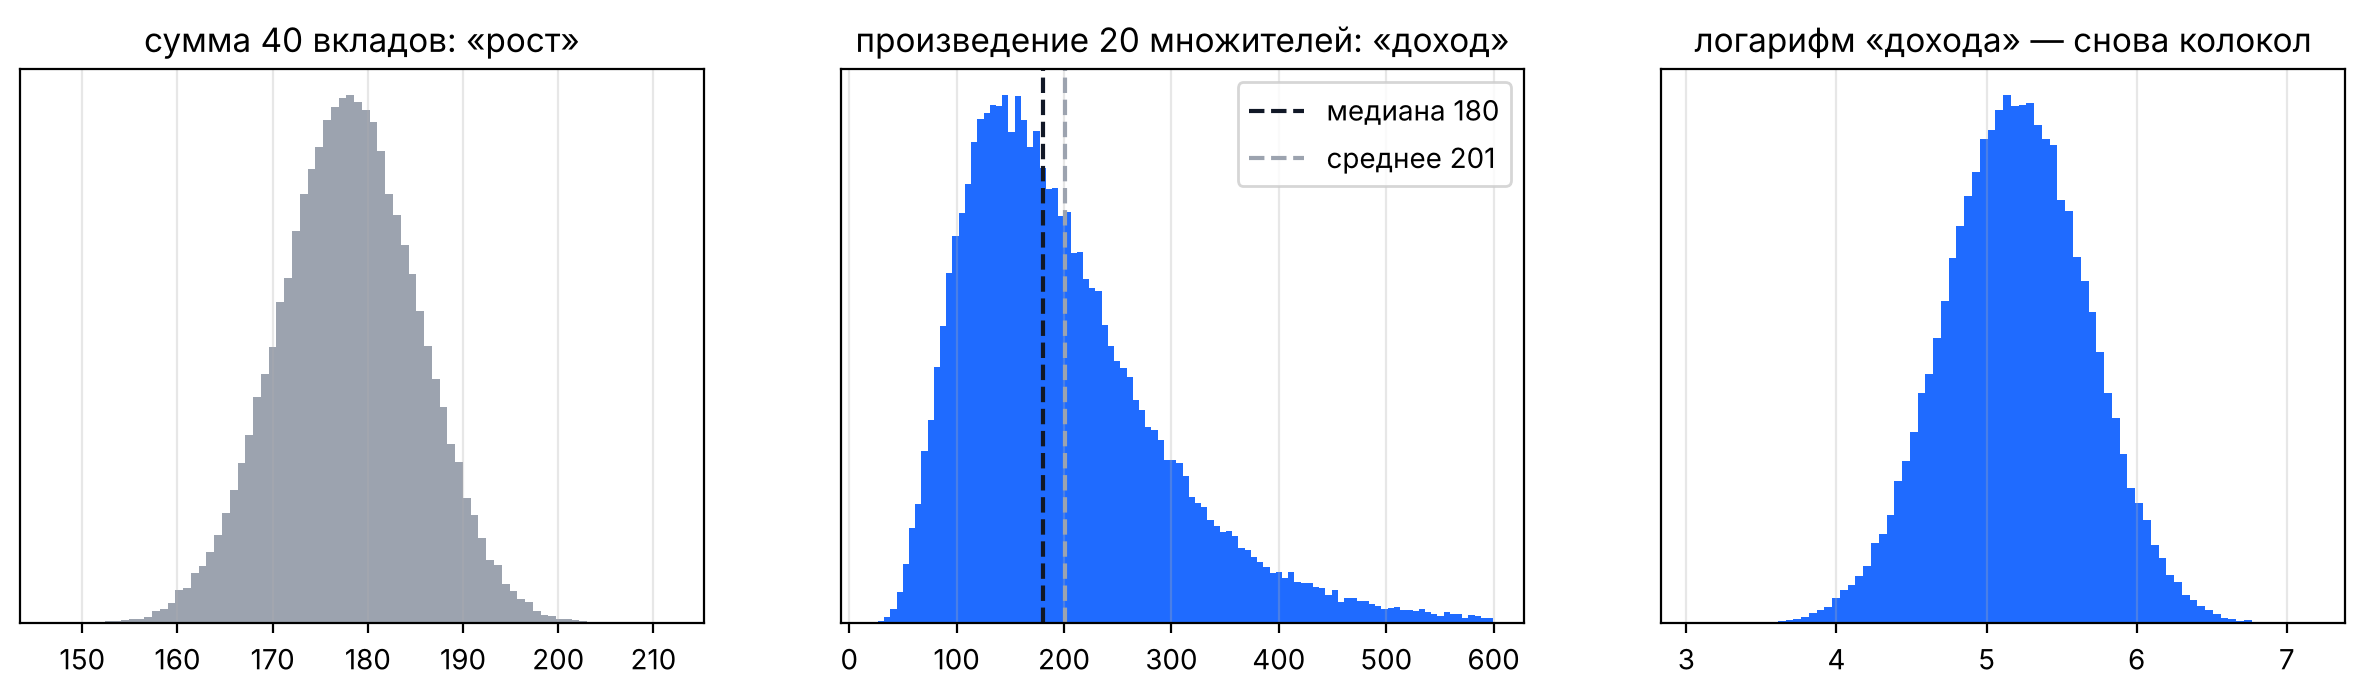

In [25]:
height = 98 + rng.uniform(0, 4, size=(100_000, 40)).sum(axis=1)
income = 30 * np.prod(1 + rng.uniform(-0.1, 0.3, size=(100_000, 20)), axis=1)
fig, axs = plt.subplots(1, 3, figsize=(15, 3.6))
axs[0].hist(height, bins=80, color=GRAY); axs[0].set_title("сумма 40 вкладов: «рост»")
axs[1].hist(income[income < 600], bins=100, color=BLUE); axs[1].set_title("произведение 20 множителей: «доход»")
axs[1].axvline(np.median(income), color=DARK, ls="--", label=f"медиана {np.median(income):.0f}")
axs[1].axvline(income.mean(), color=GRAY, ls="--", label=f"среднее {income.mean():.0f}"); axs[1].legend()
axs[2].hist(np.log(income), bins=80, color=BLUE); axs[2].set_title("логарифм «дохода» — снова колокол")
for ax in axs:
    ax.set_yticks([])
plt.show()

---
## Итоги

* **Марков и Чебышёв** дают гарантии, зная только $E(X)$ и $\mathrm{Var}(X)$. Они грубые, зато верны для любого закона.
* **Среднее** $n$ независимых наблюдений не смещено, $E(\bar X)=a$, а его разброс равен $\sigma/\sqrt n$: вчетверо больше данных — вдвое точнее.
* **ЗБЧ**: $\bar X\to a$ и $m/n\to p$, если наблюдения независимы и дисперсия конечна. Это разбавление, а не компенсация. У закона Коши ЗБЧ не работает.
* **ЦПТ**: сумма и среднее многих независимых слагаемых распределены приближённо нормально, какой бы ни была форма слагаемых. Считаем через функцию Лапласа: $P(|\bar X-a|<\delta)\approx 2\Phi(\delta\sqrt n/\sigma)$.
* Нормальной становится не гистограмма данных, а распределение среднего. Чем сильнее перекошены данные, тем больше нужно $n$.